# Projeto IA — manutenção de máquinas

## Rodada 1: Type e comparação de modelos (referência)

Estrutura original preservada: carga, exploração, divisão, pré-processamento, modelos e tabelas.
Execute de cima para baixo, com `ai4i2020.csv` na mesma pasta do notebook.
Dependências: pandas, numpy, matplotlib, seaborn, scikit-learn, imbalanced-learn e xgboost; jinja2 para as tabelas formatadas.

- Mesma divisão estratificada 60/20/20 e `random_state=42` da versão anterior.
- `Type` codificada por one-hot ajustado somente no treino.
- Resultados apresentados são de **validação**; teste reservado para a escolha final.
- Sem diferença de temperatura, potência ou desgaste × torque nesta rodada.
- A comparação final isola Random Forest, SVC RBF e XGBoost, com/sem pesos e com/sem Type.
- AP é calculada por `average_precision_score`; as tabelas originais mantêm o rótulo PR-AUC por compatibilidade.
- Dados sintéticos e divisão aleatória: estes resultados não comprovam antecipação de falhas futuras nem generalização industrial.


**Atualização:** a rodada 2 ao final acrescenta as três features físicas e compara os mesmos candidatos com a rodada 1. O conjunto de teste continua reservado; a rodada 2 transforma e avalia somente treino e validação.


**Rodada 3 ao final:** erros conjuntos, auditoria das 14 falhas da RF e regras fixas de combinação avaliadas somente na validação.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import OneHotEncoder
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("ai4i2020.csv")

df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [3]:
colunas_numericas = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

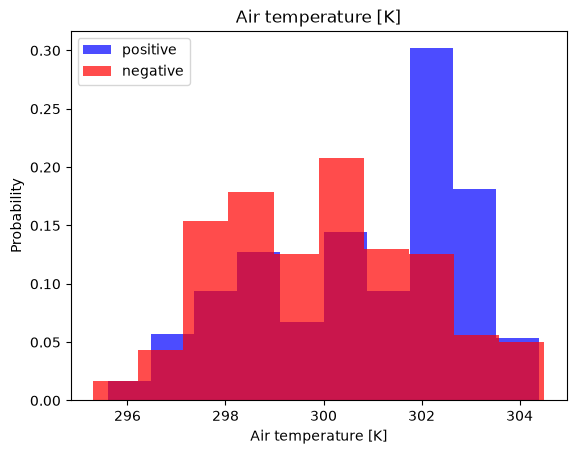

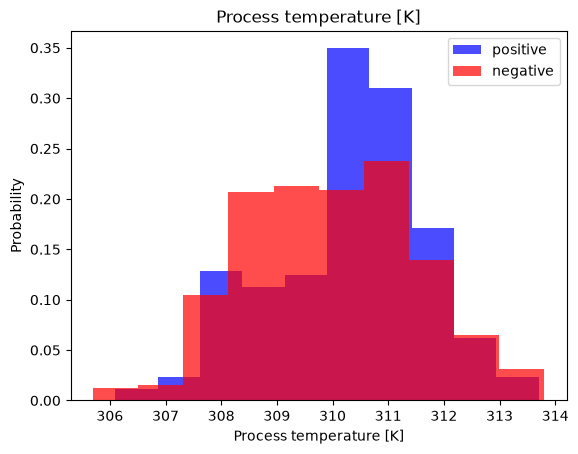

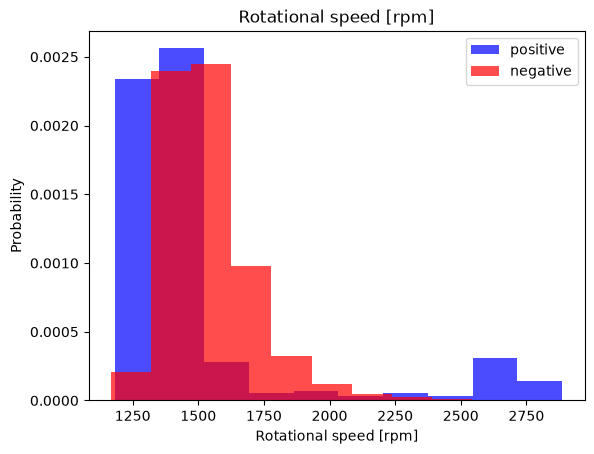

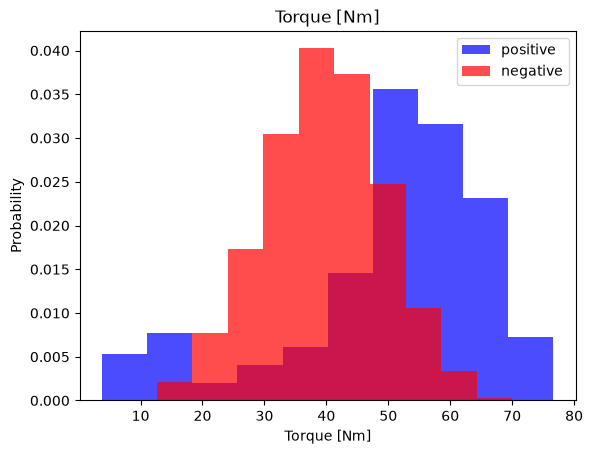

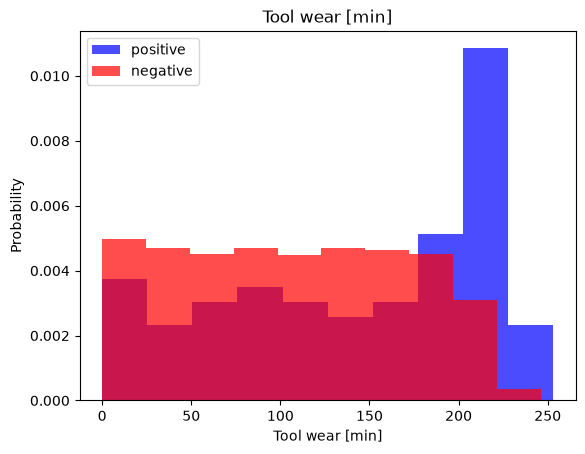

In [4]:
for label in colunas_numericas:
    if label == 'Machine failure':
        continue
    plt.hist(df[df["Machine failure"] == 1][label], color = 'blue', label = 'positive', alpha = 0.7, density = True )
    plt.hist(df[df["Machine failure"] == 0][label], color = 'red', label = 'negative', alpha = 0.7, density = True)
    plt.title(label)
    plt.ylabel("Probability")
    plt.xlabel(label)
    plt.legend()
    plt.show()

Divisão do dataset em treino, valid e test

In [5]:
X = df.drop(columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF", "Machine failure"])
y = df["Machine failure"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    #Cria 40% temporário e os 60% que sobraram serão o treino
    test_size=0.40,
    random_state=42,
    #Serve para que a proporção entre as classes seja a mesma para treino, validação e teste
    #Especialmente bom para datasets desbalanceados
    stratify=y
)
#Pega os 40% que sobraram e divide em 50% valid e 50% test
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)


In [6]:
# Type é categórica: o encoder aprende as categorias somente no treino.
# Mantemos DataFrames codificados para árvores e arrays escalados para KNN/SVC/logística.
encoder_type = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder_type.fit(X_train[["Type"]])
nomes_type = encoder_type.get_feature_names_out(["Type"])

def codificar_type(dados):
    tipos = pd.DataFrame(
        encoder_type.transform(dados[["Type"]]),
        columns=nomes_type, index=dados.index
    )
    return pd.concat([dados[colunas_numericas], tipos], axis=1)

X_train = codificar_type(X_train)
X_valid = codificar_type(X_valid)
X_test = codificar_type(X_test)

# Escalar somente as cinco variáveis numéricas; dummies continuam em 0/1.
scaler = StandardScaler()
scaler.fit(X_train[colunas_numericas])

def escalar_entradas(dados):
    return np.column_stack([
        scaler.transform(dados[colunas_numericas]),
        dados[nomes_type].to_numpy()
    ])

X_train_scaled = escalar_entradas(X_train)
X_valid_scaled = escalar_entradas(X_valid)
X_test_scaled = escalar_entradas(X_test)
print("Entradas:", X_train.columns.tolist())


Entradas: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


In [7]:
print("Treino:", X_train.shape)
print("Validação:", X_valid.shape)
print("Teste:", X_test.shape)

print("\nDistribuição treino:")
print(y_train.value_counts(normalize=True))

print("\nDistribuição validação:")
print(y_valid.value_counts(normalize=True))

print("\nDistribuição teste:")
print(y_test.value_counts(normalize=True))

Treino: (6000, 8)
Validação: (2000, 8)
Teste: (2000, 8)

Distribuição treino:
Machine failure
0    0.966167
1    0.033833
Name: proportion, dtype: float64

Distribuição validação:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64

Distribuição teste:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


In [8]:
print("Dataset completo:")
print(y.value_counts())

print("\nTreino:")
print(y_train.value_counts())

print("\nValidação:")
print(y_valid.value_counts())

print("\nTeste:")
print(y_test.value_counts())

Dataset completo:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Treino:
Machine failure
0    5797
1     203
Name: count, dtype: int64

Validação:
Machine failure
0    1932
1      68
Name: count, dtype: int64

Teste:
Machine failure
0    1932
1      68
Name: count, dtype: int64


Tratar e armazenar as métricas importantes

In [9]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

resultados_finais = {}

In [10]:
def registrar_resultado(
    nome,
    y_true,
    y_pred,
    tempo_treino,
    tempo_inferencia,
    y_score=None
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    resultado = {
        "Modelo": nome,

        "Accuracy":
            accuracy_score(y_true, y_pred),

        "Balanced Accuracy":
            balanced_accuracy_score(y_true, y_pred),

        "Precision classe 1":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "Recall classe 1":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "F1 classe 1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "Specificity":
            tn / (tn + fp),

        "MCC":
            matthews_corrcoef(
                y_true,
                y_pred
            ),

        "Falsos Negativos":
            fn,

        "Falsos Positivos":
            fp,

        "Tempo treino (s)":
            tempo_treino,

        "Tempo inferência (s)":
            tempo_inferencia
    }

    if y_score is not None:

        resultado["ROC-AUC"] = roc_auc_score(
            y_true,
            y_score
        )

        resultado["PR-AUC"] = average_precision_score(
            y_true,
            y_score
        )

    else:

        resultado["ROC-AUC"] = np.nan
        resultado["PR-AUC"] = np.nan

    # Substitui o modelo caso a célula seja executada novamente
    resultados_finais[nome] = resultado

Teste de modelos

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [12]:
knn_model = KNeighborsClassifier(
    n_neighbors=3
)

inicio = time.perf_counter()

knn_model.fit(
    X_train_scaled,
    y_train
)

tempo_treino = time.perf_counter() - inicio


inicio = time.perf_counter()

y_pred_knn = knn_model.predict(
    X_valid_scaled
)

tempo_inferencia = time.perf_counter() - inicio


y_score_knn = knn_model.predict_proba(
    X_valid_scaled
)[:, 1]


print(
    classification_report(
        y_valid,
        y_pred_knn
    )
)


registrar_resultado(
    "KNN",
    y_valid,
    y_pred_knn,
    tempo_treino,
    tempo_inferencia,
    y_score_knn
)

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1932
           1       0.54      0.31      0.39        68

    accuracy                           0.97      2000
   macro avg       0.76      0.65      0.69      2000
weighted avg       0.96      0.97      0.96      2000



In [13]:
from sklearn.naive_bayes import GaussianNB

In [14]:
nb_model = GaussianNB()

inicio = time.perf_counter()

nb_model.fit(
    X_train_scaled,
    y_train
)

tempo_treino = time.perf_counter() - inicio


inicio = time.perf_counter()

y_pred_nb = nb_model.predict(
    X_valid_scaled
)

tempo_inferencia = time.perf_counter() - inicio


y_score_nb = nb_model.predict_proba(
    X_valid_scaled
)[:, 1]


print(
    classification_report(
        y_valid,
        y_pred_nb
    )
)


registrar_resultado(
    "Naive Bayes",
    y_valid,
    y_pred_nb,
    tempo_treino,
    tempo_inferencia,
    y_score_nb
)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1932
           1       0.30      0.18      0.22        68

    accuracy                           0.96      2000
   macro avg       0.64      0.58      0.60      2000
weighted avg       0.95      0.96      0.95      2000



In [15]:
from sklearn.linear_model import LogisticRegression

In [16]:
lg_model_balanced = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

inicio = time.perf_counter()

lg_model_balanced.fit(
    X_train_scaled,
    y_train
)

tempo_treino = time.perf_counter() - inicio


inicio = time.perf_counter()

y_pred_lg_balanced = lg_model_balanced.predict(
    X_valid_scaled
)

tempo_inferencia = time.perf_counter() - inicio


y_score_lg_balanced = lg_model_balanced.predict_proba(
    X_valid_scaled
)[:, 1]


print(
    classification_report(
        y_valid,
        y_pred_lg_balanced
    )
)


registrar_resultado(
    "Logistic Regression - Balanced",
    y_valid,
    y_pred_lg_balanced,
    tempo_treino,
    tempo_inferencia,
    y_score_lg_balanced
)

              precision    recall  f1-score   support

           0       0.99      0.84      0.91      1932
           1       0.15      0.79      0.25        68

    accuracy                           0.84      2000
   macro avg       0.57      0.82      0.58      2000
weighted avg       0.96      0.84      0.89      2000



Log regression sem balanceamento

In [17]:
lg_model_unbalanced = LogisticRegression(
    class_weight=None,
    max_iter=1000,
    random_state=42
)

inicio = time.perf_counter()

lg_model_unbalanced.fit(
    X_train_scaled,
    y_train
)

tempo_treino = time.perf_counter() - inicio


inicio = time.perf_counter()

y_pred_lg_unbalanced = lg_model_unbalanced.predict(
    X_valid_scaled
)

tempo_inferencia = time.perf_counter() - inicio


y_score_lg_unbalanced = lg_model_unbalanced.predict_proba(
    X_valid_scaled
)[:, 1]


print(
    classification_report(
        y_valid,
        y_pred_lg_unbalanced
    )
)


registrar_resultado(
    "Logistic Regression - Unbalanced",
    y_valid,
    y_pred_lg_unbalanced,
    tempo_treino,
    tempo_inferencia,
    y_score_lg_unbalanced
)

              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1932
           1       0.73      0.24      0.36        68

    accuracy                           0.97      2000
   macro avg       0.85      0.62      0.67      2000
weighted avg       0.97      0.97      0.96      2000



In [18]:
# SVC com kernel RBF (não é LinearSVC).


In [19]:
from sklearn.svm import SVC

In [20]:
svm_model_balanced = SVC(
    class_weight="balanced",
    random_state=42,
    max_iter=10000
)

inicio = time.perf_counter()

svm_model_balanced.fit(
    X_train_scaled,
    y_train
)

tempo_treino = time.perf_counter() - inicio


inicio = time.perf_counter()

y_pred_svm_balanced = svm_model_balanced.predict(
    X_valid_scaled
)

tempo_inferencia = time.perf_counter() - inicio


y_score_svm_balanced = svm_model_balanced.decision_function(
    X_valid_scaled
)


print(
    classification_report(
        y_valid,
        y_pred_svm_balanced
    )
)


registrar_resultado(
    "SVC RBF - Balanced",
    y_valid,
    y_pred_svm_balanced,
    tempo_treino,
    tempo_inferencia,
    y_score_svm_balanced
)


              precision    recall  f1-score   support

           0       1.00      0.92      0.96      1932
           1       0.28      0.88      0.42        68

    accuracy                           0.92      2000
   macro avg       0.64      0.90      0.69      2000
weighted avg       0.97      0.92      0.94      2000



SVM sem balanced

In [21]:
svm_model_unbalanced = SVC(
    class_weight=None,
    random_state=42,
    max_iter=10000
)

inicio = time.perf_counter()

svm_model_unbalanced.fit(
    X_train_scaled,
    y_train
)

tempo_treino = time.perf_counter() - inicio


inicio = time.perf_counter()

y_pred_svm_unbalanced = svm_model_unbalanced.predict(
    X_valid_scaled
)

tempo_inferencia = time.perf_counter() - inicio


y_score_svm_unbalanced = svm_model_unbalanced.decision_function(
    X_valid_scaled
)


print(
    classification_report(
        y_valid,
        y_pred_svm_unbalanced
    )
)


registrar_resultado(
    "SVC RBF - Unbalanced",
    y_valid,
    y_pred_svm_unbalanced,
    tempo_treino,
    tempo_inferencia,
    y_score_svm_unbalanced
)


              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1932
           1       0.93      0.19      0.32        68

    accuracy                           0.97      2000
   macro avg       0.95      0.60      0.65      2000
weighted avg       0.97      0.97      0.96      2000



In [22]:
from sklearn.ensemble import RandomForestClassifier

In [23]:
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

inicio = time.perf_counter()

rf_balanced.fit(
    X_train,
    y_train
)

tempo_treino = time.perf_counter() - inicio


inicio = time.perf_counter()

y_pred_rf_balanced = rf_balanced.predict(
    X_valid
)

tempo_inferencia = time.perf_counter() - inicio


y_score_rf_balanced = rf_balanced.predict_proba(
    X_valid
)[:, 1]


print(
    classification_report(
        y_valid,
        y_pred_rf_balanced
    )
)


registrar_resultado(
    "Random Forest - Balanced",
    y_valid,
    y_pred_rf_balanced,
    tempo_treino,
    tempo_inferencia,
    y_score_rf_balanced
)

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1932
           1       0.53      0.66      0.59        68

    accuracy                           0.97      2000
   macro avg       0.76      0.82      0.79      2000
weighted avg       0.97      0.97      0.97      2000



Random forest sem balanceamento

In [24]:
rf_unbalanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

inicio = time.perf_counter()

rf_unbalanced.fit(
    X_train,
    y_train
)

tempo_treino = time.perf_counter() - inicio


inicio = time.perf_counter()

y_pred_rf_unbalanced = rf_unbalanced.predict(
    X_valid
)

tempo_inferencia = time.perf_counter() - inicio


y_score_rf_unbalanced = rf_unbalanced.predict_proba(
    X_valid
)[:, 1]


print(
    classification_report(
        y_valid,
        y_pred_rf_unbalanced
    )
)


registrar_resultado(
    "Random Forest - Unbalanced",
    y_valid,
    y_pred_rf_unbalanced,
    tempo_treino,
    tempo_inferencia,
    y_score_rf_unbalanced
)

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.88      0.34      0.49        68

    accuracy                           0.98      2000
   macro avg       0.93      0.67      0.74      2000
weighted avg       0.97      0.98      0.97      2000



## XGBoost

Comparação com e sem pesos. Parâmetros fixos nesta rodada, sem busca de hiperparâmetros, reamostragem ou ajuste de limiar. `Balanced` usa `scale_pos_weight = negativos / positivos` do treino.


In [25]:
from xgboost import XGBClassifier

# Pesos calculados exclusivamente a partir do treino.
peso_positivo = (y_train == 0).sum() / (y_train == 1).sum()
parametros_xgb = dict(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    objective="binary:logistic", eval_metric="logloss",
    tree_method="hist", random_state=42, n_jobs=4
)

def avaliar_modelo(nome, modelo, entradas_treino, entradas_valid):
    inicio = time.perf_counter()
    modelo.fit(entradas_treino, y_train)
    tempo_treino = time.perf_counter() - inicio
    inicio = time.perf_counter()
    pred = modelo.predict(entradas_valid)
    tempo_inferencia = time.perf_counter() - inicio
    score = (modelo.predict_proba(entradas_valid)[:, 1]
             if hasattr(modelo, "predict_proba")
             else modelo.decision_function(entradas_valid))
    registrar_resultado(nome, y_valid, pred, tempo_treino, tempo_inferencia, score)
    return pred

# Arrays evitam a restrição do XGBoost a colchetes nos nomes das features.
xgb_unbalanced = XGBClassifier(**parametros_xgb, scale_pos_weight=1)
xgb_balanced = XGBClassifier(**parametros_xgb, scale_pos_weight=peso_positivo)
for nome, modelo in [
    ("XGBoost - Unbalanced", xgb_unbalanced),
    ("XGBoost - Balanced", xgb_balanced)
]:
    pred = avaliar_modelo(nome, modelo, X_train.to_numpy(), X_valid.to_numpy())
    print(nome)
    print(classification_report(y_valid, pred))


XGBoost - Unbalanced
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.88      0.56      0.68        68

    accuracy                           0.98      2000
   macro avg       0.93      0.78      0.84      2000
weighted avg       0.98      0.98      0.98      2000



XGBoost - Balanced
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1932
           1       0.42      0.82      0.56        68

    accuracy                           0.96      2000
   macro avg       0.71      0.89      0.77      2000
weighted avg       0.97      0.96      0.96      2000



In [26]:
df_resultados = pd.DataFrame(
    resultados_finais.values()
).reset_index(drop=True)

df_resultados

,Modelo,Accuracy,Balanced Accuracy,Precision classe 1,Recall classe 1,F1 classe 1,Specificity,MCC,Falsos Negativos,Falsos Positivos,Tempo treino (s),Tempo inferência (s),ROC-AUC,PR-AUC
0,KNN,0.9675,0.649753,0.538462,0.308824,0.392523,0.990683,0.392549,47,18,0.005187,0.013977,0.792888,0.337061
1,Naive Bayes,0.9580,0.580989,0.300000,0.176471,0.222222,0.985507,0.209679,56,28,0.001434,0.000301,0.832686,0.252115
2,Logistic Regression - Balanced,0.8410,0.818384,0.150838,0.794118,0.253521,0.842650,0.301031,14,304,0.008407,0.000238,0.881051,0.407168
3,Logistic Regression - Unbalanced,0.9710,0.616094,0.727273,0.235294,0.355556,0.996894,0.403436,52,6,0.009341,0.000226,0.873714,0.432080
4,SVC RBF - Balanced,0.9180,0.900804,0.277778,0.882353,0.422535,0.919255,0.468054,8,156,0.192292,0.108961,0.960008,0.578756
5,SVC RBF - Unbalanced,0.9720,0.595329,0.928571,0.191176,0.317073,0.999482,0.414440,55,1,0.067407,0.034943,0.946406,0.616658
6,Random Forest - Balanced,0.9685,0.820530,0.529412,0.661765,0.588235,0.979296,0.575922,23,40,0.309491,0.048933,0.955806,0.614762
7,Random Forest - Unbalanced,0.9760,0.668341,0.884615,0.338235,0.489362,0.998447,0.538664,45,3,0.280135,0.038393,0.965877,0.726237
8,XGBoost - Unbalanced,0.9825,0.778118,0.883721,0.558824,0.684685,0.997412,0.695004,30,5,0.764106,0.005075,0.970413,0.764814
9,XGBoost - Balanced,0.9555,0.891837,0.421053,0.823529,0.557214,0.960145,0.570027,12,77,0.711328,0.003936,0.962847,0.692054


In [27]:
print(
    df_resultados[
        "Modelo"
    ].to_string(index=False)
)

print(
    "\nTotal:",
    len(df_resultados),
    "modelos/configurações"
)

                             KNN
                     Naive Bayes
  Logistic Regression - Balanced
Logistic Regression - Unbalanced
              SVC RBF - Balanced
            SVC RBF - Unbalanced
        Random Forest - Balanced
      Random Forest - Unbalanced
            XGBoost - Unbalanced
              XGBoost - Balanced

Total: 10 modelos/configurações


In [28]:
tabela_geral = df_resultados[[
    "Modelo",
    "Accuracy",
    "Balanced Accuracy",
    "ROC-AUC",
    "PR-AUC",
    "MCC"
]].copy()

tabela_geral

,Modelo,Accuracy,Balanced Accuracy,ROC-AUC,PR-AUC,MCC
0,KNN,0.9675,0.649753,0.792888,0.337061,0.392549
1,Naive Bayes,0.9580,0.580989,0.832686,0.252115,0.209679
2,Logistic Regression - Balanced,0.8410,0.818384,0.881051,0.407168,0.301031
3,Logistic Regression - Unbalanced,0.9710,0.616094,0.873714,0.432080,0.403436
4,SVC RBF - Balanced,0.9180,0.900804,0.960008,0.578756,0.468054
5,SVC RBF - Unbalanced,0.9720,0.595329,0.946406,0.616658,0.414440
6,Random Forest - Balanced,0.9685,0.820530,0.955806,0.614762,0.575922
7,Random Forest - Unbalanced,0.9760,0.668341,0.965877,0.726237,0.538664
8,XGBoost - Unbalanced,0.9825,0.778118,0.970413,0.764814,0.695004
9,XGBoost - Balanced,0.9555,0.891837,0.962847,0.692054,0.570027


In [29]:
tabela_geral.style.format({
    "Accuracy": "{:.2%}",
    "Balanced Accuracy": "{:.2%}",
    "ROC-AUC": "{:.3f}",
    "PR-AUC": "{:.3f}",
    "MCC": "{:.3f}"
}).hide(axis="index")

Modelo,Accuracy,Balanced Accuracy,ROC-AUC,PR-AUC,MCC
KNN,96.75%,64.98%,0.793,0.337,0.393
Naive Bayes,95.80%,58.10%,0.833,0.252,0.210
Logistic Regression - Balanced,84.10%,81.84%,0.881,0.407,0.301
Logistic Regression - Unbalanced,97.10%,61.61%,0.874,0.432,0.403
SVC RBF - Balanced,91.80%,90.08%,0.960,0.579,0.468
SVC RBF - Unbalanced,97.20%,59.53%,0.946,0.617,0.414
Random Forest - Balanced,96.85%,82.05%,0.956,0.615,0.576
Random Forest - Unbalanced,97.60%,66.83%,0.966,0.726,0.539
XGBoost - Unbalanced,98.25%,77.81%,0.970,0.765,0.695
XGBoost - Balanced,95.55%,89.18%,0.963,0.692,0.570


In [30]:
tabela_classe_1 = df_resultados[[
    "Modelo",
    "Precision classe 1",
    "Recall classe 1",
    "F1 classe 1",
    "Falsos Negativos",
    "Falsos Positivos"
]].copy()

In [31]:
tabela_classe_1.style.format({
    "Precision classe 1": "{:.2%}",
    "Recall classe 1": "{:.2%}",
    "F1 classe 1": "{:.2%}",
    "Falsos Negativos": "{:,.0f}",
    "Falsos Positivos": "{:,.0f}"
}).hide(axis="index")

Modelo,Precision classe 1,Recall classe 1,F1 classe 1,Falsos Negativos,Falsos Positivos
KNN,53.85%,30.88%,39.25%,47,18
Naive Bayes,30.00%,17.65%,22.22%,56,28
Logistic Regression - Balanced,15.08%,79.41%,25.35%,14,304
Logistic Regression - Unbalanced,72.73%,23.53%,35.56%,52,6
SVC RBF - Balanced,27.78%,88.24%,42.25%,8,156
SVC RBF - Unbalanced,92.86%,19.12%,31.71%,55,1
Random Forest - Balanced,52.94%,66.18%,58.82%,23,40
Random Forest - Unbalanced,88.46%,33.82%,48.94%,45,3
XGBoost - Unbalanced,88.37%,55.88%,68.47%,30,5
XGBoost - Balanced,42.11%,82.35%,55.72%,12,77


<Figure size 1400x700 with 0 Axes>

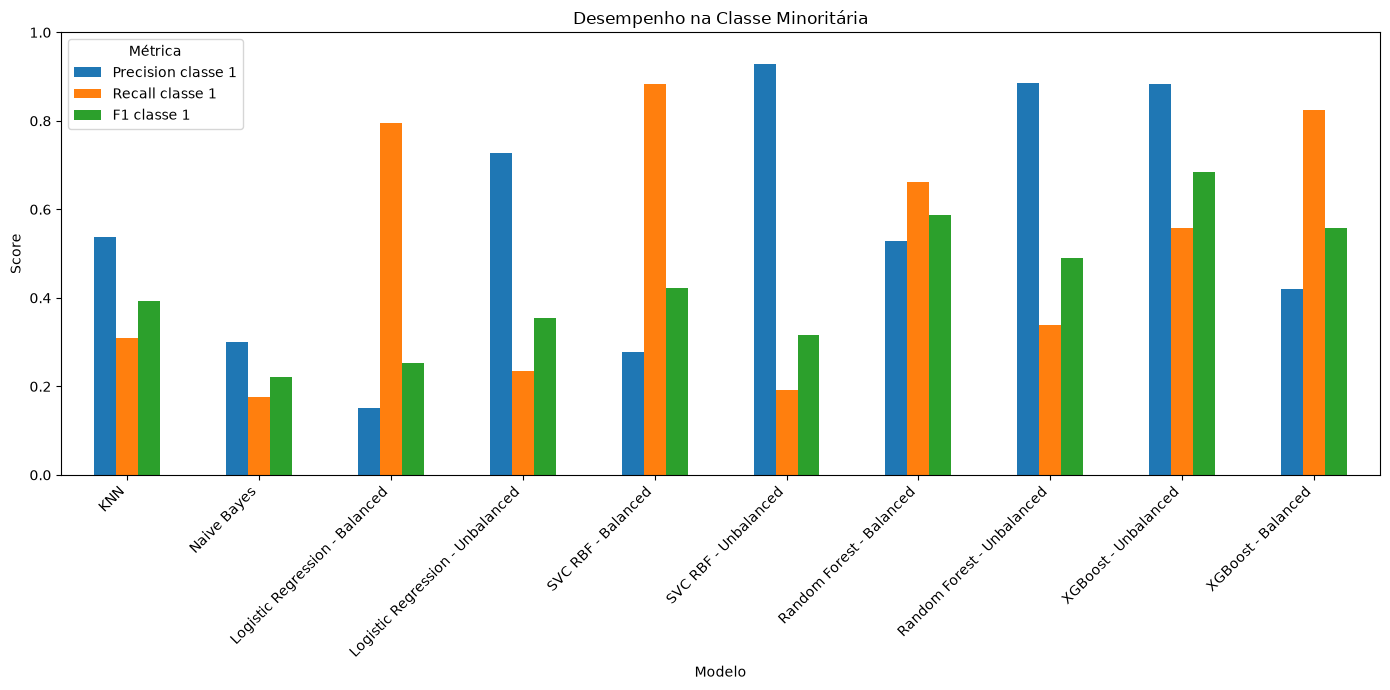

In [32]:
plt.figure(figsize=(14, 7))

tabela_classe_1_plot = tabela_classe_1.set_index("Modelo")[
    [
        "Precision classe 1",
        "Recall classe 1",
        "F1 classe 1"
    ]
]

tabela_classe_1_plot.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Desempenho na Classe Minoritária")
plt.ylabel("Score")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

In [33]:
tabela_tempo = df_resultados[[
    "Modelo",
    "Tempo treino (s)",
    "Tempo inferência (s)"
]].copy()

tabela_tempo.style.format({
    "Tempo treino (s)": "{:.4f}",
    "Tempo inferência (s)": "{:.4f}"
}).hide(axis="index")

Modelo,Tempo treino (s),Tempo inferência (s)
KNN,0.0052,0.0140
Naive Bayes,0.0014,0.0003
Logistic Regression - Balanced,0.0084,0.0002
Logistic Regression - Unbalanced,0.0093,0.0002
SVC RBF - Balanced,0.1923,0.1090
SVC RBF - Unbalanced,0.0674,0.0349
Random Forest - Balanced,0.3095,0.0489
Random Forest - Unbalanced,0.2801,0.0384
XGBoost - Unbalanced,0.7641,0.0051
XGBoost - Balanced,0.7113,0.0039


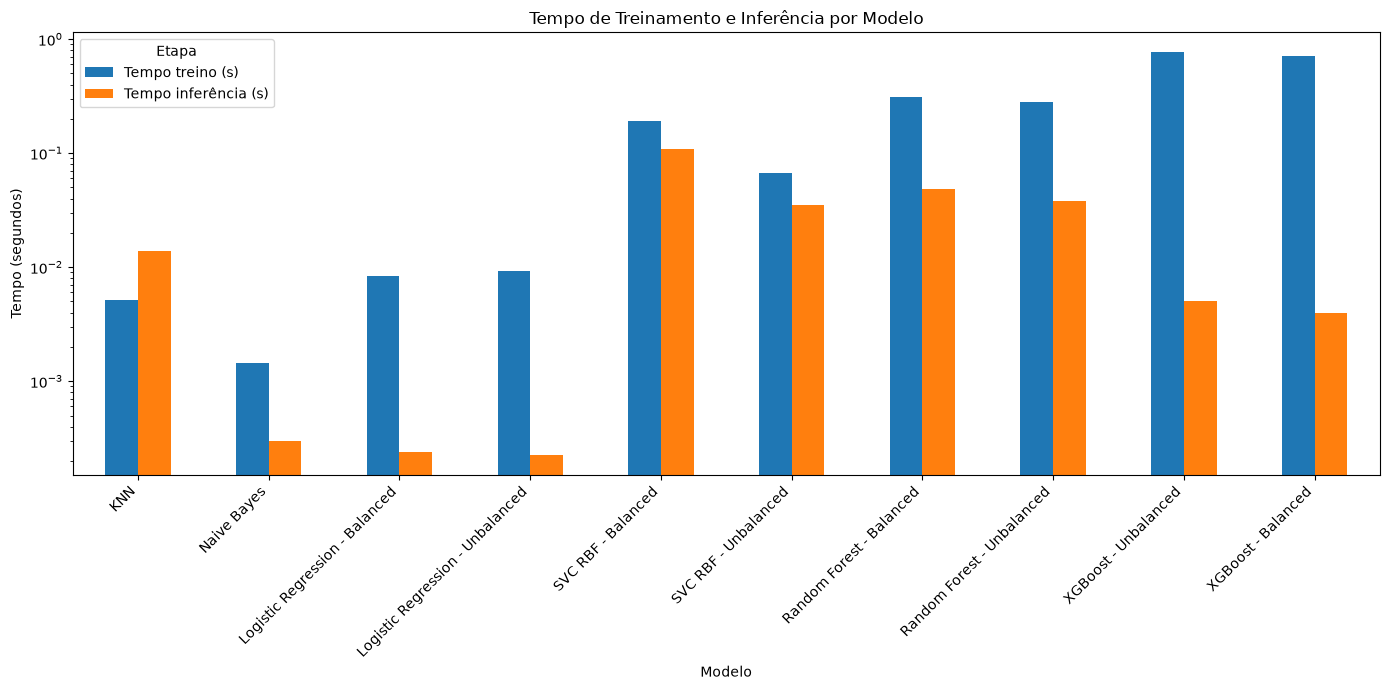

In [34]:
tabela_tempo_plot = tabela_tempo.set_index("Modelo")[
    [
        "Tempo treino (s)",
        "Tempo inferência (s)"
    ]
]

tabela_tempo_plot.plot(
    kind="bar",
    figsize=(14, 7),
    logy = True
)

plt.title("Tempo de Treinamento e Inferência por Modelo")
plt.ylabel("Tempo (segundos)")
plt.xlabel("Modelo")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Etapa")
plt.tight_layout()
plt.show()

In [35]:
tabela_executiva = df_resultados[[
    "Modelo",
    "Accuracy",
    "Recall classe 1",
    "Precision classe 1",
    "F1 classe 1",
    "PR-AUC",
    "Tempo treino (s)"
]].copy()

tabela_executiva.style.format({
    "Accuracy": "{:.2%}",
    "Recall classe 1": "{:.2%}",
    "Precision classe 1": "{:.2%}",
    "F1 classe 1": "{:.2%}",
    "PR-AUC": "{:.3f}",
    "Tempo treino (s)": "{:.3f}"
}).hide(axis="index")

Modelo,Accuracy,Recall classe 1,Precision classe 1,F1 classe 1,PR-AUC,Tempo treino (s)
KNN,96.75%,30.88%,53.85%,39.25%,0.337,0.005
Naive Bayes,95.80%,17.65%,30.00%,22.22%,0.252,0.001
Logistic Regression - Balanced,84.10%,79.41%,15.08%,25.35%,0.407,0.008
Logistic Regression - Unbalanced,97.10%,23.53%,72.73%,35.56%,0.432,0.009
SVC RBF - Balanced,91.80%,88.24%,27.78%,42.25%,0.579,0.192
SVC RBF - Unbalanced,97.20%,19.12%,92.86%,31.71%,0.617,0.067
Random Forest - Balanced,96.85%,66.18%,52.94%,58.82%,0.615,0.309
Random Forest - Unbalanced,97.60%,33.82%,88.46%,48.94%,0.726,0.280
XGBoost - Unbalanced,98.25%,55.88%,88.37%,68.47%,0.765,0.764
XGBoost - Balanced,95.55%,82.35%,42.11%,55.72%,0.692,0.711


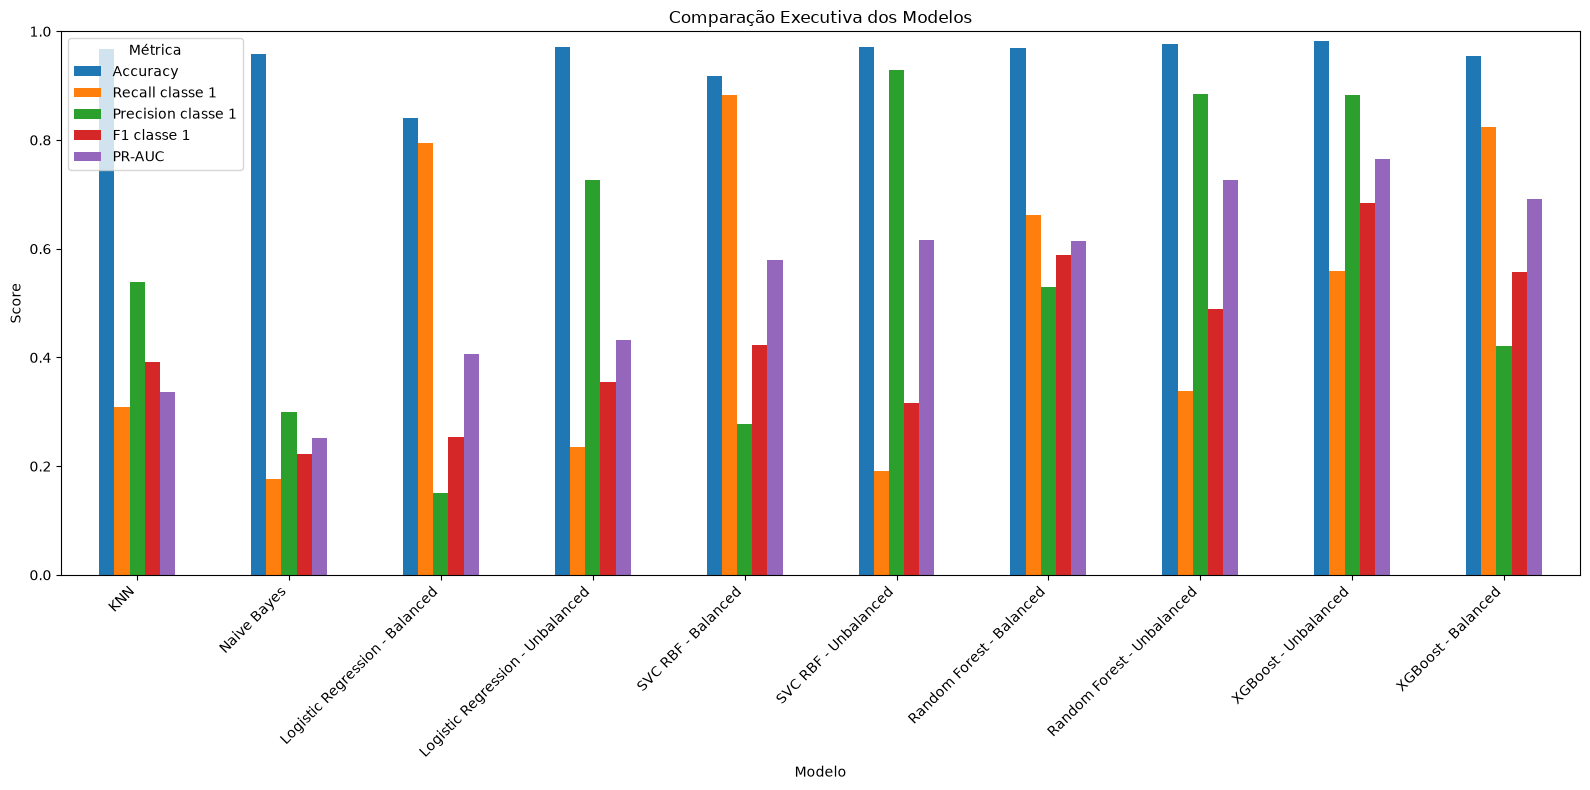

In [36]:
tabela_executiva_plot = tabela_executiva.set_index("Modelo")[
    [
        "Accuracy",
        "Recall classe 1",
        "Precision classe 1",
        "F1 classe 1",
        "PR-AUC"
    ]
]

tabela_executiva_plot.plot(
    kind="bar",
    figsize=(16, 8)
)

plt.title("Comparação Executiva dos Modelos")
plt.ylabel("Score")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

## Comparação focada: Random Forest, SVC RBF e XGBoost


In [37]:
colunas_comparacao = [
    "Modelo", "Precision classe 1", "Recall classe 1", "F1 classe 1",
    "Falsos Negativos", "Falsos Positivos", "PR-AUC", "ROC-AUC", "MCC"
]
foco = df_resultados["Modelo"].str.startswith(("Random Forest", "SVC RBF", "XGBoost"))
comparacao_3_modelos = df_resultados.loc[foco, colunas_comparacao].copy()
comparacao_3_modelos = comparacao_3_modelos.sort_values("PR-AUC", ascending=False)
comparacao_3_modelos


,Modelo,Precision classe 1,Recall classe 1,F1 classe 1,Falsos Negativos,Falsos Positivos,PR-AUC,ROC-AUC,MCC
8,XGBoost - Unbalanced,0.883721,0.558824,0.684685,30,5,0.764814,0.970413,0.695004
7,Random Forest - Unbalanced,0.884615,0.338235,0.489362,45,3,0.726237,0.965877,0.538664
9,XGBoost - Balanced,0.421053,0.823529,0.557214,12,77,0.692054,0.962847,0.570027
5,SVC RBF - Unbalanced,0.928571,0.191176,0.317073,55,1,0.616658,0.946406,0.414440
6,Random Forest - Balanced,0.529412,0.661765,0.588235,23,40,0.614762,0.955806,0.575922
4,SVC RBF - Balanced,0.277778,0.882353,0.422535,8,156,0.578756,0.960008,0.468054


## Experimento controlado: contribuição de Type

Repetimos somente os três candidatos (com/sem pesos), nas mesmas linhas e com os mesmos parâmetros, retirando as dummies de Type. Nenhum dado de teste é usado. Para SVC, o `gamma="scale"` padrão é recalculado ao mudar as entradas: a comparação mede o efeito na configuração padrão do algoritmo.


In [38]:
# Preservar os resultados principais; registrar os novos temporariamente no mesmo helper.
resultados_com_type = resultados_finais.copy()
treino_sem_type = X_train[colunas_numericas]
valid_sem_type = X_valid[colunas_numericas]
treino_sem_type_scaled = scaler.transform(treino_sem_type)
valid_sem_type_scaled = scaler.transform(valid_sem_type)
modelos_sem_type = [
    ("Random Forest - Balanced", RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=42, n_jobs=-1), treino_sem_type, valid_sem_type),
    ("Random Forest - Unbalanced", RandomForestClassifier(n_estimators=200, max_depth=10, class_weight=None, random_state=42, n_jobs=-1), treino_sem_type, valid_sem_type),
    ("SVC RBF - Balanced", SVC(class_weight="balanced", random_state=42, max_iter=10000), treino_sem_type_scaled, valid_sem_type_scaled),
    ("SVC RBF - Unbalanced", SVC(class_weight=None, random_state=42, max_iter=10000), treino_sem_type_scaled, valid_sem_type_scaled),
    ("XGBoost - Balanced", XGBClassifier(**parametros_xgb, scale_pos_weight=peso_positivo), treino_sem_type.to_numpy(), valid_sem_type.to_numpy()),
    ("XGBoost - Unbalanced", XGBClassifier(**parametros_xgb, scale_pos_weight=1), treino_sem_type.to_numpy(), valid_sem_type.to_numpy())
]
try:
    for nome, modelo, treino, valid in modelos_sem_type:
        avaliar_modelo(nome, modelo, treino, valid)
    resultados_sem_type = pd.DataFrame([resultados_finais[nome].copy() for nome, *_ in modelos_sem_type])
finally:
    resultados_finais = resultados_com_type

comparacao_type = pd.concat([
    df_resultados.loc[foco].assign(Entradas="Com Type"),
    resultados_sem_type.assign(Entradas="Sem Type")
], ignore_index=True)
comparacao_type = comparacao_type.sort_values(["Modelo", "Entradas"])
comparacao_type[["Modelo", "Entradas", "Precision classe 1", "Recall classe 1", "F1 classe 1", "PR-AUC", "Falsos Negativos", "Falsos Positivos"]]


,Modelo,Entradas,Precision classe 1,Recall classe 1,F1 classe 1,PR-AUC,Falsos Negativos,Falsos Positivos
2,Random Forest - Balanced,Com Type,0.529412,0.661765,0.588235,0.614762,23,40
6,Random Forest - Balanced,Sem Type,0.488636,0.632353,0.551282,0.683737,25,45
3,Random Forest - Unbalanced,Com Type,0.884615,0.338235,0.489362,0.726237,45,3
7,Random Forest - Unbalanced,Sem Type,0.820513,0.470588,0.598131,0.751565,36,7
0,SVC RBF - Balanced,Com Type,0.277778,0.882353,0.422535,0.578756,8,156
8,SVC RBF - Balanced,Sem Type,0.291080,0.911765,0.441281,0.603893,6,151
1,SVC RBF - Unbalanced,Com Type,0.928571,0.191176,0.317073,0.616658,55,1
9,SVC RBF - Unbalanced,Sem Type,0.882353,0.220588,0.352941,0.653203,53,2
5,XGBoost - Balanced,Com Type,0.421053,0.823529,0.557214,0.692054,12,77
10,XGBoost - Balanced,Sem Type,0.442748,0.852941,0.582915,0.719989,10,73


## Leitura dos resultados e próximos passos

Compare recall com o número de falsos alarmes, além de F1, AP e MCC. Maior recall sozinho não define o melhor modelo. AP avalia a ordenação dos scores em vários limiares; precisão, recall e F1 apresentados usam a decisão padrão de cada modelo.

São apenas 68 falhas na validação: cada falha equivale a aproximadamente 1,47 ponto percentual de recall. Não há vencedor definitivo nem avaliação final de teste nesta rodada. Antes da integração, avaliar estabilidade e sensibilidade à ordem dos registros. As três features físicas ficam para a próxima etapa.


## Resultados desta execução

**XGBoost sem pesos e sem Type** teve o maior F1 (0,719), AP (0,789) e MCC (0,726) entre as 12 configurações focadas. Identificou 41/68 falhas, perdeu 27 e gerou 5 falsos alarmes. É um candidato para a próxima etapa, ainda com recall de apenas 60,3%.

Com Type, o XGBoost sem pesos identificou 38/68 falhas, perdeu 30 e gerou os mesmos 5 falsos alarmes; F1=0,685 e AP=0,765. Não há evidência de ganho geral ao incluir Type nesta rodada: a AP caiu em todas as seis configurações. A Random Forest com pesos ganhou recall (63,2% → 66,2%) e F1 (0,551 → 0,588), mas perdeu AP (0,684 → 0,615).

Para priorizar detecção, o SVC RBF com pesos e sem Type encontrou 62/68 falhas, com 151 falsos alarmes; o XGBoost com pesos e sem Type encontrou 58/68, com 73 falsos alarmes. A escolha depende do custo dos erros e ainda exige comparação de limiares.

As comparações com/sem Type acima foram executadas no mesmo ambiente. Não confundir diferenças em relação às saídas antigas com efeito exclusivo de Type: versões das bibliotecas também podem modificar resultados. A execução atual usa scikit-learn 1.9.1 e XGBoost 3.4.1; a Random Forest com pesos sem Type desta execução difere da saída antiga. Não foi executada busca de hiperparâmetros. Teste permanece reservado.


# Rodada 2 — features físicas

Preservamos as células anteriores como referência. Mesmas linhas de treino e validação, sementes, hiperparâmetros e limiares padrão. Testamos os três modelos com e sem pesos, tanto com Type quanto sem Type (12 configurações).

Features criadas somente a partir de medições disponíveis na entrada:

- `temp_diff`: temperatura do processo − temperatura do ar, em K.
- `power_w`: torque × rotação × 2π/60, em W (conversão de rpm para rad/s).
- `wear_x_torque`: desgaste × torque, em min·Nm.

Nenhum modo de falha entra como feature. As fórmulas são conhecimento de domínio do simulador. O scaler é ajustado somente no treino, incluindo as novas features; dummies Type permanecem em 0/1. Não há previsão, métrica ou ajuste com o teste nesta rodada.

In [39]:
features_derivadas = ["temp_diff", "power_w", "wear_x_torque"]
numericas_features = colunas_numericas + features_derivadas

def criar_features_fisicas(dados):
    resultado = dados.copy()
    resultado["temp_diff"] = resultado["Process temperature [K]"] - resultado["Air temperature [K]"]
    resultado["power_w"] = resultado["Torque [Nm]"] * resultado["Rotational speed [rpm]"] * (2 * np.pi / 60)
    resultado["wear_x_torque"] = resultado["Tool wear [min]"] * resultado["Torque [Nm]"]
    return resultado

# X_train e X_valid já têm o one-hot de Type, ajustado no treino na rodada 1.
X_train_features = criar_features_fisicas(X_train)
X_valid_features = criar_features_fisicas(X_valid)
scaler_features = StandardScaler()
scaler_features.fit(X_train_features[numericas_features])

def preparar_features_svc(dados, usar_type):
    numericas = scaler_features.transform(dados[numericas_features])
    return np.column_stack([numericas, dados[nomes_type].to_numpy()]) if usar_type else numericas

# Verificações das fórmulas e do isolamento das partições.
assert X_train_features.index.equals(y_train.index)
assert X_valid_features.index.equals(y_valid.index)
assert set(X_train_features.index).isdisjoint(X_valid_features.index)
for dados in [X_train_features, X_valid_features]:
    assert np.isfinite(dados[numericas_features].to_numpy()).all()
    np.testing.assert_allclose(dados["power_w"], dados["Torque [Nm]"] * dados["Rotational speed [rpm]"] * 2 * np.pi / 60)
    np.testing.assert_allclose(dados["temp_diff"], dados["Process temperature [K]"] - dados["Air temperature [K]"])
    np.testing.assert_allclose(dados["wear_x_torque"], dados["Tool wear [min]"] * dados["Torque [Nm]"])
print("Treino:", len(X_train_features), "| Validação:", len(X_valid_features))
X_train_features[numericas_features].describe()

Treino: 6000 | Validação: 2000


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_diff,power_w,wear_x_torque
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,300.019783,310.012383,1538.869500,40.034067,107.492833,9.992600,6285.675712,4304.505417
std,2.004329,1.479536,180.530086,10.035769,63.571628,1.004865,1073.137522,2828.078876
min,295.300000,305.700000,1168.000000,3.800000,0.000000,7.600000,1148.440610,0.000000
25%,298.300000,308.800000,1422.000000,33.200000,52.000000,9.300000,5555.576741,1923.000000
50%,300.100000,310.100000,1503.000000,40.100000,107.000000,9.800000,6271.844158,4002.000000
75%,301.500000,311.100000,1614.000000,46.900000,162.000000,11.000000,7018.365112,6283.600000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,12.100000,10469.923005,16497.000000


## Random Forest, SVC RBF e XGBoost — com e sem pesos

`Balanced` mantém os mecanismos da rodada 1: `class_weight="balanced"` para RF/SVC e `scale_pos_weight` calculado no treino para XGBoost. Sem busca de hiperparâmetros ou ajuste de limiar. No SVC, `gamma="scale"` acompanha as entradas; na RF, a amostragem padrão de features também depende da dimensão. A comparação mede a adição de features às configurações atuais.

In [40]:
resultados_features = []
modelos_features = {}
resultados_rodada1 = resultados_finais.copy()
try:
    for usar_type in [False, True]:
        entradas = "Com Type" if usar_type else "Sem Type"
        colunas = numericas_features + (list(nomes_type) if usar_type else [])
        treino_arvores = X_train_features[colunas]
        valid_arvores = X_valid_features[colunas]
        treino_svc = preparar_features_svc(X_train_features, usar_type)
        valid_svc = preparar_features_svc(X_valid_features, usar_type)
        for com_pesos in [False, True]:
            sufixo = "Balanced" if com_pesos else "Unbalanced"
            peso_classe = "balanced" if com_pesos else None
            candidatos = [
                ("Random Forest", RandomForestClassifier(n_estimators=200, max_depth=10, class_weight=peso_classe, random_state=42, n_jobs=-1), treino_arvores, valid_arvores),
                ("SVC RBF", SVC(class_weight=peso_classe, random_state=42, max_iter=10000), treino_svc, valid_svc),
                ("XGBoost", XGBClassifier(**parametros_xgb, scale_pos_weight=peso_positivo if com_pesos else 1), treino_arvores.to_numpy(), valid_arvores.to_numpy())
            ]
            for familia, modelo, treino, valid in candidatos:
                nome = f"{familia} - {sufixo}"
                avaliar_modelo(nome, modelo, treino, valid)
                linha = resultados_finais[nome].copy()
                linha.update(Entradas=entradas, Features="Com derivadas")
                resultados_features.append(linha)
                modelos_features[(nome, entradas)] = modelo
                print(f"{nome} | {entradas}: recall={linha['Recall classe 1']:.1%}, F1={linha['F1 classe 1']:.3f}, AP={linha['PR-AUC']:.3f}")
finally:
    resultados_finais = resultados_rodada1

df_resultados_features = pd.DataFrame(resultados_features)
colunas_features = ["Modelo", "Entradas", "Precision classe 1", "Recall classe 1", "F1 classe 1", "PR-AUC", "MCC", "Falsos Negativos", "Falsos Positivos"]
df_resultados_features[colunas_features].sort_values("F1 classe 1", ascending=False)

Random Forest - Unbalanced | Sem Type: recall=76.5%, F1=0.846, AP=0.868
SVC RBF - Unbalanced | Sem Type: recall=29.4%, F1=0.440, AP=0.713


XGBoost - Unbalanced | Sem Type: recall=76.5%, F1=0.825, AP=0.840


Random Forest - Balanced | Sem Type: recall=79.4%, F1=0.766, AP=0.839


SVC RBF - Balanced | Sem Type: recall=89.7%, F1=0.452, AP=0.572


XGBoost - Balanced | Sem Type: recall=83.8%, F1=0.691, AP=0.802


Random Forest - Unbalanced | Com Type: recall=79.4%, F1=0.878, AP=0.873
SVC RBF - Unbalanced | Com Type: recall=26.5%, F1=0.404, AP=0.687


XGBoost - Unbalanced | Com Type: recall=77.9%, F1=0.828, AP=0.850


Random Forest - Balanced | Com Type: recall=77.9%, F1=0.763, AP=0.842


SVC RBF - Balanced | Com Type: recall=89.7%, F1=0.462, AP=0.578


XGBoost - Balanced | Com Type: recall=83.8%, F1=0.691, AP=0.812


,Modelo,Entradas,Precision classe 1,Recall classe 1,F1 classe 1,PR-AUC,MCC,Falsos Negativos,Falsos Positivos
6,Random Forest - Unbalanced,Com Type,0.981818,0.794118,0.878049,0.873354,0.879465,14,1
0,Random Forest - Unbalanced,Sem Type,0.945455,0.764706,0.845528,0.867723,0.845724,16,3
8,XGBoost - Unbalanced,Com Type,0.883333,0.779412,0.828125,0.849798,0.824185,15,7
2,XGBoost - Unbalanced,Sem Type,0.896552,0.764706,0.825397,0.840435,0.822520,16,6
3,Random Forest - Balanced,Sem Type,0.739726,0.794118,0.765957,0.838630,0.757929,14,19
9,Random Forest - Balanced,Com Type,0.746479,0.779412,0.762590,0.841901,0.754236,15,18
11,XGBoost - Balanced,Com Type,0.587629,0.838235,0.690909,0.811829,0.689695,11,40
5,XGBoost - Balanced,Sem Type,0.587629,0.838235,0.690909,0.802296,0.689695,11,40
10,SVC RBF - Balanced,Com Type,0.311224,0.897059,0.462121,0.578419,0.504212,7,135
4,SVC RBF - Balanced,Sem Type,0.301980,0.897059,0.451852,0.572328,0.495628,7,141


## Comparação direta com a rodada sem features derivadas

Comparações pareadas por modelo, pesos e inclusão de Type. Deltas positivos em F1/AP/recall indicam aumento; em falsos negativos/positivos indicam mais erros. Todos os resultados são da mesma validação.

In [41]:
base_features = comparacao_type.assign(Features="Sem derivadas")
comparacao_features = pd.concat([base_features, df_resultados_features], ignore_index=True)
metricas_delta = ["Precision classe 1", "Recall classe 1", "F1 classe 1", "PR-AUC", "Falsos Negativos", "Falsos Positivos"]
impacto_features = df_resultados_features[["Modelo", "Entradas"] + metricas_delta].merge(
    base_features[["Modelo", "Entradas"] + metricas_delta],
    on=["Modelo", "Entradas"], suffixes=(" com derivadas", " sem derivadas"), validate="one_to_one"
)
for metrica in metricas_delta:
    impacto_features["Delta " + metrica] = impacto_features[metrica + " com derivadas"] - impacto_features[metrica + " sem derivadas"]
impacto_features[["Modelo", "Entradas"] + ["Delta " + m for m in metricas_delta]]

,Modelo,Entradas,Delta Precision classe 1,Delta Recall classe 1,Delta F1 classe 1,Delta PR-AUC,Delta Falsos Negativos,Delta Falsos Positivos
0,Random Forest - Unbalanced,Sem Type,0.124942,0.294118,0.247398,0.116158,-20,-4
1,SVC RBF - Unbalanced,Sem Type,-0.012788,0.073529,0.086619,0.059812,-5,1
2,XGBoost - Unbalanced,Sem Type,0.005247,0.161765,0.106099,0.050988,-11,1
3,Random Forest - Balanced,Sem Type,0.251090,0.161765,0.214675,0.154893,-11,-26
4,SVC RBF - Balanced,Sem Type,0.010900,-0.014706,0.010571,-0.031566,1,-10
5,XGBoost - Balanced,Sem Type,0.144881,-0.014706,0.107995,0.082306,1,-33
6,Random Forest - Unbalanced,Com Type,0.097203,0.455882,0.388687,0.147118,-31,-2
7,SVC RBF - Unbalanced,Com Type,-0.071429,0.073529,0.087421,0.070821,-5,2
8,XGBoost - Unbalanced,Com Type,-0.000388,0.220588,0.143440,0.084984,-15,2
9,Random Forest - Balanced,Com Type,0.217067,0.117647,0.174355,0.227139,-8,-22


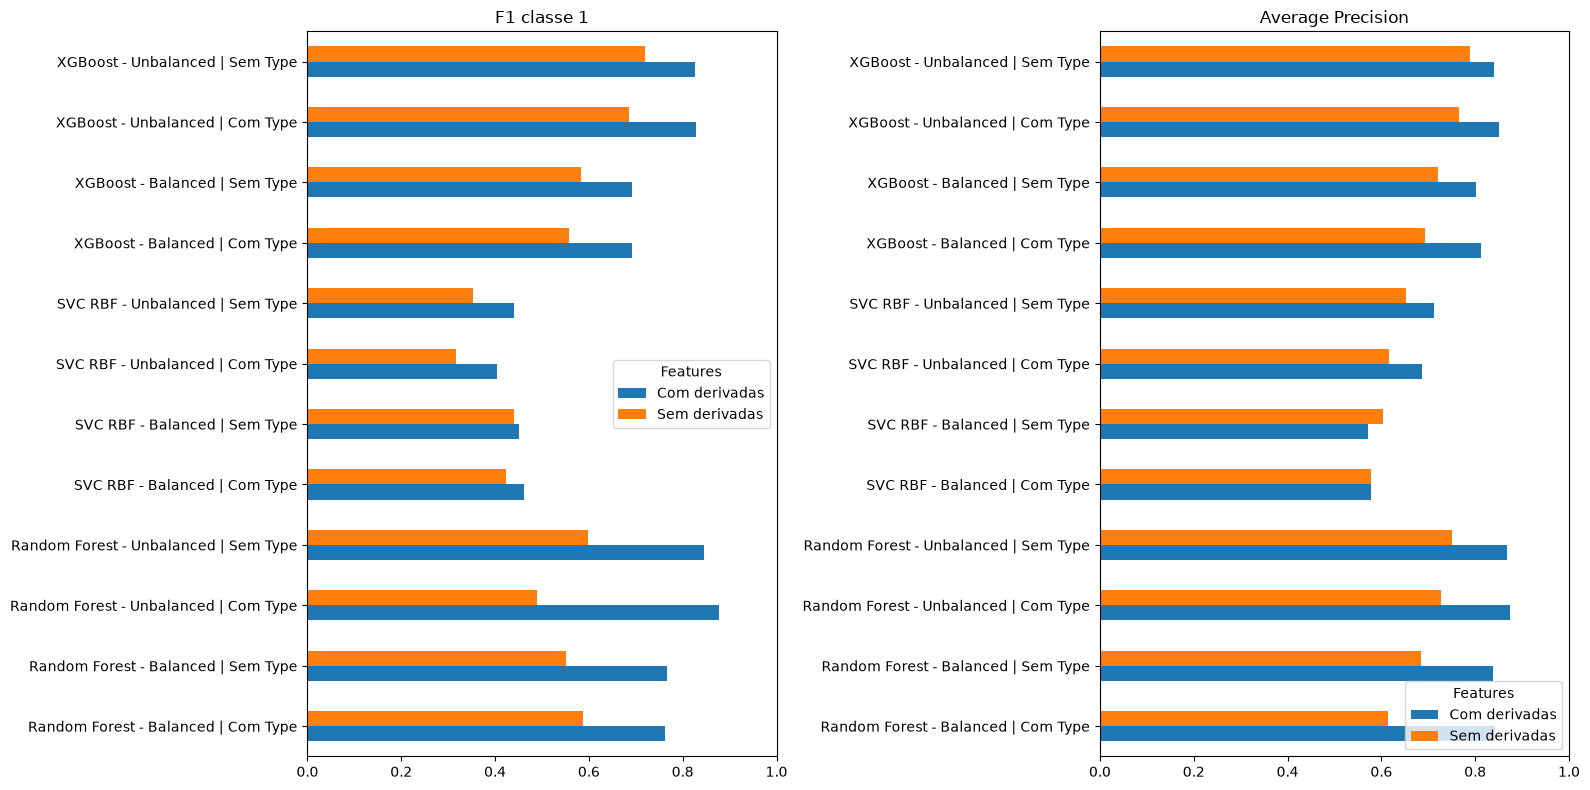

In [42]:
comparacao_features_plot = comparacao_features.copy()
comparacao_features_plot["Configuração"] = comparacao_features_plot["Modelo"] + " | " + comparacao_features_plot["Entradas"]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, metrica in zip(axes, ["F1 classe 1", "PR-AUC"]):
    comparacao_features_plot.pivot(index="Configuração", columns="Features", values=metrica).plot.barh(ax=ax)
    ax.set_xlim(0, 1)
    ax.set_title("Average Precision" if metrica == "PR-AUC" else metrica)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## Resultados da rodada 2 — features físicas

Maior F1 nesta validação: **Random Forest - Unbalanced | Com Type**, com precisão 98.2%, recall 79.4%, F1 0.878 e AP 0.873. Encontrou 54/68 falhas, perdeu 14 e gerou 1 falsos alarmes.

Na mesma configuração sem derivadas: F1 0.489, AP 0.726, 45 falhas perdidas e 3 falsos alarmes.

As novas features expressam regras usadas para gerar este dataset sintético. Melhora aqui não demonstra generalização industrial nem capacidade de prever falhas com antecedência. São apenas 68 falhas na validação e já comparamos várias configurações nela; não tratar a melhor métrica como estimativa final independente. O teste continua reservado, sem predições ou métricas nesta rodada.


# Rodada 3 — erros conjuntos e combinações na validação

Referência: **Random Forest sem pesos, com Type e as três derivadas** (14 falhas perdidas na rodada anterior). Usamos as predições dos modelos já treinados na rodada 2, sem treinar um meta-modelo e sem acessar o teste.

A comparação principal usa os seis modelos com Type. Como análise complementar, incluímos os seis sem Type. Para cada candidato, contamos quais falhas perdidas pela referência ele recupera, quais falhas que a referência acertava ele perde, os erros compartilhados e os falsos alarmes adicionais ao usar OU.

As regras de combinação são fixas sobre as classes previstas nos limiares padrão: OU, E e votos mínimos. Não usamos o alvo para escolher uma resposta por registro. Uma união que cobre mais falhas ainda pode gerar muitos falsos alarmes. Esta análise explora a mesma validação já usada para comparar modelos; não é avaliação final independente.

In [43]:
# Predições somente na validação; a ordem é fixada por y_valid.index.
predicoes_conjuntas = pd.DataFrame(index=y_valid.index)
for (nome, entradas), modelo in modelos_features.items():
    usar_type = entradas == "Com Type"
    colunas = numericas_features + (list(nomes_type) if usar_type else [])
    if nome.startswith("SVC RBF"):
        dados_valid = preparar_features_svc(X_valid_features, usar_type)
    elif nome.startswith("XGBoost"):
        dados_valid = X_valid_features[colunas].to_numpy()
    else:
        dados_valid = X_valid_features[colunas]
    predicoes_conjuntas[f"{nome} | {entradas}"] = modelo.predict(dados_valid).astype(int)

referencia_conjunta = "Random Forest - Unbalanced | Com Type"
positivos_valid = y_valid.eq(1)
negativos_valid = y_valid.eq(0)
pred_ref = predicoes_conjuntas[referencia_conjunta].eq(1)
falhas_perdidas_ref = positivos_valid & ~pred_ref
nomes_principais = [c for c in predicoes_conjuntas if c.endswith("| Com Type")]
nomes_sem_type = [c for c in predicoes_conjuntas if c.endswith("| Sem Type")]
assert len(predicoes_conjuntas) == len(y_valid) == 2000
assert len(nomes_principais) == len(nomes_sem_type) == 6
assert int(falhas_perdidas_ref.sum()) == 14

erros_conjuntos = []
for nome in predicoes_conjuntas:
    candidato = predicoes_conjuntas[nome].eq(1)
    recuperadas = falhas_perdidas_ref & candidato
    erros_conjuntos.append({
        "Modelo": nome,
        "Recupera das 14 perdidas": int(recuperadas.sum()),
        "Continua perdendo das 14": int((falhas_perdidas_ref & ~candidato).sum()),
        "Perde falhas que RF acerta": int((positivos_valid & pred_ref & ~candidato).sum()),
        "Falsos alarmes candidato": int((negativos_valid & candidato).sum()),
        "Falsos alarmes novos no OU": int((negativos_valid & ~pred_ref & candidato).sum()),
        "UDI recuperados": ", ".join(df.loc[recuperadas[recuperadas].index,"UDI"].astype(str))
    })
erros_conjuntos = pd.DataFrame(erros_conjuntos)
erros_conjuntos[erros_conjuntos.Modelo.isin(nomes_principais)]

,Modelo,Recupera das 14 perdidas,Continua perdendo das 14,Perde falhas que RF acerta,Falsos alarmes candidato,Falsos alarmes novos no OU,UDI recuperados
6,Random Forest - Unbalanced | Com Type,0,14,0,1,0,
7,SVC RBF - Unbalanced | Com Type,0,14,36,3,3,
8,XGBoost - Unbalanced | Com Type,0,14,1,7,6,
9,Random Forest - Balanced | Com Type,0,14,1,18,17,
10,SVC RBF - Balanced | Com Type,7,7,0,135,134,"2865, 7427, 8691, 6000, 1510, 9016, 4035"
11,XGBoost - Balanced | Com Type,3,11,0,40,39,"2865, 6000, 4035"


In [44]:
# Matriz: quantas falhas cada par perde simultaneamente.
falhas_nao_detectadas = predicoes_conjuntas.loc[positivos_valid].eq(0).astype(int)
falhas_perdidas_em_comum = falhas_nao_detectadas.T.dot(falhas_nao_detectadas)
falhas_perdidas_em_comum.loc[nomes_principais, nomes_principais]

,Random Forest - Unbalanced | Com Type,SVC RBF - Unbalanced | Com Type,XGBoost - Unbalanced | Com Type,Random Forest - Balanced | Com Type,SVC RBF - Balanced | Com Type,XGBoost - Balanced | Com Type
Random Forest - Unbalanced | Com Type,14,14,14,14,7,11
SVC RBF - Unbalanced | Com Type,14,50,15,15,7,11
XGBoost - Unbalanced | Com Type,14,15,15,14,7,11
Random Forest - Balanced | Com Type,14,15,14,15,7,11
SVC RBF - Balanced | Com Type,7,7,7,7,7,7
XGBoost - Balanced | Com Type,11,11,11,11,7,11


In [45]:
# Auditoria das 14 falhas perdidas pela referência, identificadas pelo UDI.
auditoria_falhas_rf = df.loc[falhas_perdidas_ref[falhas_perdidas_ref].index,
    ["UDI", "Type"] + colunas_numericas].copy()
auditoria_falhas_rf = auditoria_falhas_rf.join(predicoes_conjuntas)
auditoria_falhas_rf["Detectada por algum dos 6 com Type"] = auditoria_falhas_rf[nomes_principais].any(axis=1)
auditoria_falhas_rf["Detectada por algum dos 12"] = auditoria_falhas_rf[predicoes_conjuntas.columns].any(axis=1)
auditoria_falhas_rf

,UDI,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Random Forest - Unbalanced | Sem Type,SVC RBF - Unbalanced | Sem Type,XGBoost - Unbalanced | Sem Type,...,SVC RBF - Balanced | Sem Type,XGBoost - Balanced | Sem Type,Random Forest - Unbalanced | Com Type,SVC RBF - Unbalanced | Com Type,XGBoost - Unbalanced | Com Type,Random Forest - Balanced | Com Type,SVC RBF - Balanced | Com Type,XGBoost - Balanced | Com Type,Detectada por algum dos 6 com Type,Detectada por algum dos 12
8199,8200,L,299.2,310.7,1737,27.0,225,0,0,0,...,0,0,0,0,0,0,0,0,False,False
2864,2865,H,300.6,309.4,1380,47.6,246,0,0,1,...,1,1,0,0,0,0,1,1,True,True
2671,2672,M,299.7,309.3,1399,41.9,221,0,0,0,...,1,0,0,0,0,0,0,0,False,True
4684,4685,M,303.6,311.8,1421,44.8,101,0,0,0,...,0,0,0,0,0,0,0,0,False,False
7426,7427,M,300.0,311.4,1692,29.0,216,0,0,0,...,0,0,0,0,0,0,1,0,True,True
8690,8691,L,297.1,308.5,1323,44.4,207,0,0,0,...,1,0,0,0,0,0,1,0,True,True
9174,9175,L,297.8,308.9,1871,25.6,200,0,0,0,...,0,0,0,0,0,0,0,0,False,False
5999,6000,M,300.4,310.2,1671,30.5,234,0,0,0,...,1,1,0,0,0,0,1,1,True,True
8506,8507,L,298.4,309.6,1710,27.3,163,0,0,0,...,0,0,0,0,0,0,0,0,False,False
2941,2942,M,300.7,309.6,1996,19.8,203,0,0,0,...,0,0,0,0,0,0,0,0,False,False


## Regras fixas de combinação

Comparamos os modelos individuais, OU/E de cada candidato com a referência, votos dos seis modelos com Type, maioria dos três sem pesos e dos três com pesos. Também mostramos OU/E da referência com as variantes sem Type, identificadas como complementares.

Os votos não são independentes: todos os modelos usam as mesmas medições e várias configurações pertencem à mesma família. Uma votação de seis configurações não significa seis fontes independentes de evidência. Não calculamos AP/ROC-AUC para regras binárias; esses indicadores exigem scores adequados à comparação.

In [46]:
regras_conjuntas = {}
grupos_regras = {}
def adicionar_regra(nome, pred, grupo):
    pred = pd.Series(np.asarray(pred, dtype=int), index=y_valid.index)
    assert pred.isin([0,1]).all() and len(pred)==len(y_valid)
    regras_conjuntas[nome] = pred
    grupos_regras[nome] = grupo

for nome in nomes_principais:
    adicionar_regra(nome, predicoes_conjuntas[nome], "Individual com Type")
for nome in predicoes_conjuntas:
    if nome == referencia_conjunta: continue
    grupo = "Par com Type" if nome in nomes_principais else "Par complementar sem Type"
    adicionar_regra(f"RF referência OU ({nome})", pred_ref | predicoes_conjuntas[nome].eq(1), grupo)
    adicionar_regra(f"RF referência E ({nome})", pred_ref & predicoes_conjuntas[nome].eq(1), grupo)

votos_seis = predicoes_conjuntas[nomes_principais].sum(axis=1)
for minimo in range(1,7):
    adicionar_regra(f"Pelo menos {minimo} dos 6 com Type", votos_seis.ge(minimo), "Votos com Type")
for sufixo, titulo in [("Unbalanced", "sem pesos"), ("Balanced", "com pesos")]:
    nomes = [c for c in nomes_principais if f"- {sufixo} |" in c]
    assert len(nomes)==3
    for minimo in [1,2,3]:
        adicionar_regra(f"Pelo menos {minimo} dos 3 {titulo} com Type", predicoes_conjuntas[nomes].sum(axis=1).ge(minimo), "Votos por família")
adicionar_regra("OU dos 12 (com e sem Type)", predicoes_conjuntas.any(axis=1), "Complementar 12 modelos")

metricas_regras = []
for nome, pred in regras_conjuntas.items():
    tn,fp,fn,tp = confusion_matrix(y_valid,pred,labels=[0,1]).ravel()
    metricas_regras.append({"Regra":nome, "Grupo":grupos_regras[nome],
        "Precisão":precision_score(y_valid,pred,zero_division=0),
        "Recall":recall_score(y_valid,pred), "F1":f1_score(y_valid,pred),
        "MCC":matthews_corrcoef(y_valid,pred),
        "Falhas encontradas":int(tp),"Falhas perdidas":int(fn),
        "Falsos alarmes":int(fp),"Total alertas":int(tp+fp),
        "Recuperadas vs RF":int((falhas_perdidas_ref & pred.eq(1)).sum()),
        "Falhas antes certas agora perdidas":int((positivos_valid & pred_ref & pred.eq(0)).sum())})
comparacao_regras = pd.DataFrame(metricas_regras).sort_values(["F1","Recall"],ascending=False).reset_index(drop=True)
assert (comparacao_regras["Falhas encontradas"]+comparacao_regras["Falhas perdidas"]).eq(68).all()
comparacao_regras[~comparacao_regras.Grupo.isin(["Par complementar sem Type","Complementar 12 modelos"])]

,Regra,Grupo,Precisão,Recall,F1,MCC,Falhas encontradas,Falhas perdidas,Falsos alarmes,Total alertas,Recuperadas vs RF,Falhas antes certas agora perdidas
0,Random Forest - Unbalanced | Com Type,Individual com Type,0.981818,0.794118,0.878049,0.879465,54,14,1,55,0,0
3,RF referência E (SVC RBF - Balanced | Com Type),Par com Type,0.981818,0.794118,0.878049,0.879465,54,14,1,55,0,0
4,RF referência E (XGBoost - Balanced | Com Type),Par com Type,0.981818,0.794118,0.878049,0.879465,54,14,1,55,0,0
6,RF referência E (XGBoost - Unbalanced | Com Type),Par com Type,0.981481,0.779412,0.868852,0.870900,53,15,1,54,0,1
7,RF referência E (Random Forest - Balanced | Co...,Par com Type,0.981481,0.779412,0.868852,0.870900,53,15,1,54,0,1
9,Pelo menos 2 dos 3 sem pesos com Type,Votos por família,0.963636,0.779412,0.861789,0.862594,53,15,2,55,0,1
12,RF referência OU (SVC RBF - Unbalanced | Com T...,Par com Type,0.931034,0.794118,0.857143,0.855402,54,14,4,58,0,0
14,Pelo menos 5 dos 6 com Type,Votos com Type,0.962963,0.764706,0.852459,0.853878,52,16,2,54,0,2
16,Pelo menos 4 dos 6 com Type,Votos com Type,0.900000,0.794118,0.843750,0.840359,54,14,6,60,0,0
17,RF referência OU (XGBoost - Unbalanced | Com T...,Par com Type,0.885246,0.794118,0.837209,0.833111,54,14,7,61,0,0


## Triagem com três respostas: RF e XGBoost sem pesos, com Type

Concordância positiva → alerta; divergência → revisão; concordância negativa → sem alerta dos modelos. Mantemos as três categorias separadas: revisão não é um acerto automático. Se revisão for tratada como sinalização, a regra equivale a OU; se apenas concordância positiva gerar sinalização, equivale a E.

In [47]:
pred_xgb = predicoes_conjuntas["XGBoost - Unbalanced | Com Type"].eq(1)
triagem = pd.Series("Sem alerta dos modelos",index=y_valid.index)
triagem.loc[pred_ref ^ pred_xgb] = "Revisão (divergência)"
triagem.loc[pred_ref & pred_xgb] = "Alerta (ambos positivos)"
comparacao_triagem = pd.crosstab(triagem,y_valid).reindex(columns=[0,1],fill_value=0)
comparacao_triagem.columns = ["Sem falha real", "Com falha real"]
comparacao_triagem["Total"] = comparacao_triagem.sum(axis=1)
comparacao_triagem

,Sem falha real,Com falha real,Total
row_0,,,
Alerta (ambos positivos),1,53,54
Revisão (divergência),6,1,7
Sem alerta dos modelos,1925,14,1939


In [48]:
# Regras não dominadas em falhas perdidas/falsos alarmes (igualdades são preservadas).
def regra_nao_dominada(linha):
    melhor_ou_igual = (comparacao_regras["Falhas perdidas"] <= linha["Falhas perdidas"]) & (comparacao_regras["Falsos alarmes"] <= linha["Falsos alarmes"])
    estritamente_melhor = (comparacao_regras["Falhas perdidas"] < linha["Falhas perdidas"]) | (comparacao_regras["Falsos alarmes"] < linha["Falsos alarmes"])
    return not (melhor_ou_igual & estritamente_melhor).any()
fronteira_regras = comparacao_regras[comparacao_regras.apply(regra_nao_dominada,axis=1)].copy()
fronteira_regras.sort_values(["Falhas perdidas","Falsos alarmes"])

,Regra,Grupo,Precisão,Recall,F1,MCC,Falhas encontradas,Falhas perdidas,Falsos alarmes,Total alertas,Recuperadas vs RF,Falhas antes certas agora perdidas
36,OU dos 12 (com e sem Type),Complementar 12 modelos,0.279279,0.911765,0.427586,0.478237,62,6,160,222,8,0
30,SVC RBF - Balanced | Com Type,Individual com Type,0.311224,0.897059,0.462121,0.504212,61,7,135,196,7,0
31,RF referência OU (SVC RBF - Balanced | Com Type),Par com Type,0.311224,0.897059,0.462121,0.504212,61,7,135,196,7,0
25,Pelo menos 2 dos 3 com pesos com Type,Votos por família,0.612903,0.838235,0.708075,0.705414,57,11,36,93,3,0
13,RF referência OU (XGBoost - Unbalanced | Sem T...,Par complementar sem Type,0.901639,0.808824,0.852713,0.849156,55,13,6,61,1,0
0,Random Forest - Unbalanced | Com Type,Individual com Type,0.981818,0.794118,0.878049,0.879465,54,14,1,55,0,0
1,RF referência E (SVC RBF - Balanced | Sem Type),Par complementar sem Type,0.981818,0.794118,0.878049,0.879465,54,14,1,55,0,0
2,RF referência E (XGBoost - Balanced | Sem Type),Par complementar sem Type,0.981818,0.794118,0.878049,0.879465,54,14,1,55,0,0
3,RF referência E (SVC RBF - Balanced | Com Type),Par com Type,0.981818,0.794118,0.878049,0.879465,54,14,1,55,0,0
4,RF referência E (XGBoost - Balanced | Com Type),Par com Type,0.981818,0.794118,0.878049,0.879465,54,14,1,55,0,0


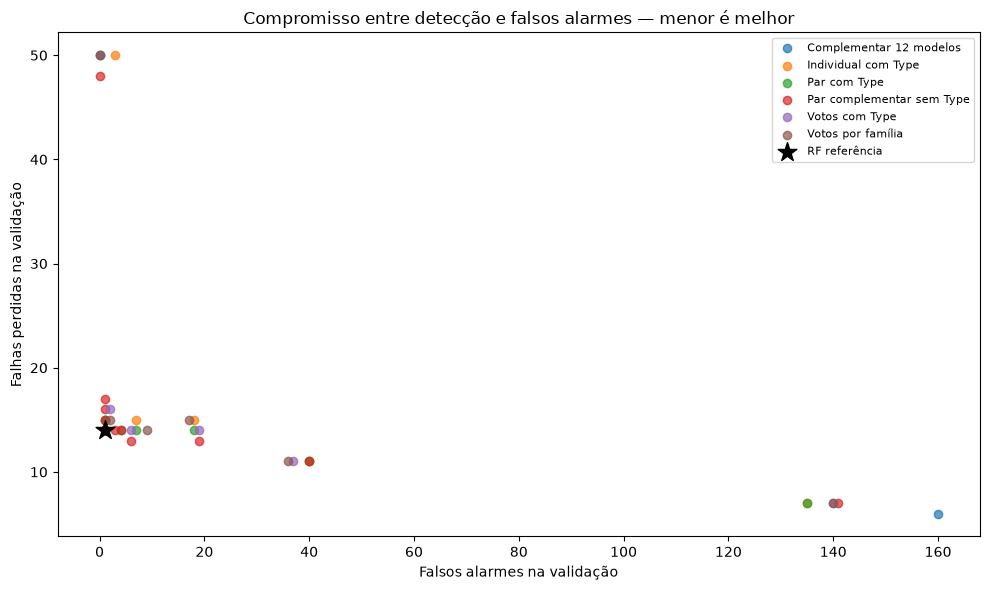

In [49]:
fig,ax = plt.subplots(figsize=(10,6))
for grupo,dados in comparacao_regras.groupby("Grupo"):
    ax.scatter(dados["Falsos alarmes"],dados["Falhas perdidas"],label=grupo,alpha=0.7)
ax.scatter(int((negativos_valid & pred_ref).sum()),int(falhas_perdidas_ref.sum()),marker="*",s=200,color="black",label="RF referência")
ax.set_xlabel("Falsos alarmes na validação")
ax.set_ylabel("Falhas perdidas na validação")
ax.set_title("Compromisso entre detecção e falsos alarmes — menor é melhor")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Resultados da rodada 3 — complementaridade e regras

**A RF sem pesos com Type continua com o maior F1 entre as regras avaliadas: 0,878 (54/68 falhas, 14 perdidas, 1 falso alarme).** Combinar modelos não melhorou esse equilíbrio na validação atual.

- XGBoost sem pesos com Type recupera **0/14** falhas perdidas pela RF; RF com pesos com Type também recupera 0/14. Seus alertas positivos extras só acrescentam falsos alarmes no OU.
- SVC com pesos com Type recupera **7/14**, mas adiciona **134 falsos alarmes** aos da referência. OU: 61/68 falhas e 135 falsos alarmes, igual ao SVC sozinho nesta validação.
- XGBoost com pesos com Type recupera **3/14**, com **39 falsos alarmes adicionais**. OU: 57/68 e 40 falsos alarmes, igual ao XGBoost com pesos sozinho nesta validação.
- XGBoost sem pesos sem Type recupera **1/14**, com 5 falsos alarmes adicionais. OU: 55/68, 13 perdidas, 6 falsos alarmes; F1=0,853.
- Maioria dos três modelos com pesos e Type: **57/68**, 11 perdidas e **36 falsos alarmes**; F1=0,708. Tem os mesmos acertos positivos do XGBoost com pesos nesta validação e quatro falsos alarmes a menos.
- OU dos seis com Type: 61/68 e 140 falsos alarmes, sem recuperar falhas além do SVC com pesos. OU dos 12: **62/68**, 6 perdidas e **160 falsos alarmes**. As seis restantes passam por todos os modelos nos limiares atuais; isso não demonstra que sejam impossíveis de detectar com outra configuração.

Triagem RF/XGBoost sem pesos com Type: concordância positiva em 54 casos (53 falhas e 1 sem falha); divergência em 7 (1 falha e 6 sem falha); concordância negativa em 1.939 (14 falhas e 1.925 sem falha). Revisar divergências não recuperaria nenhuma das 14 falhas perdidas pela RF nesta validação: a única falha divergente já é sinalizada pela RF.

Nenhuma regra melhora simultaneamente a detecção e o número de falsos alarmes da referência. Não existe escolha operacional única sem definir custos de falha perdida/inspeção. Os resultados são exploratórios na mesma validação, sem uso do teste. Devem orientar a próxima avaliação de estabilidade e de limiar; não comprovam ganho fora desta amostra.


# Rodada 4 — estabilidade da Random Forest sem pesos

Configuração fixa: 200 árvores, max_depth=10, sem pesos, Type e três derivadas. Não há seleção de hiperparâmetros nem ajuste de limiar.

1. **Sensibilidade à divisão:** 20 divisões estratificadas, sempre 6.000 para treino e 2.000 para validação, dentro dos 8.000 registros de desenvolvimento (treino + validação originais).
2. **Sensibilidade à semente:** 10 sementes da floresta no treino/validação originais, mantendo os dados fixos.
3. **Blocos ordenados:** quatro janelas de validação progressivas na ordem do UDI, dentro do desenvolvimento, com gap de 30 registros de desenvolvimento. O gap é uma verificação de sensibilidade, sem significado de horas/dias. Esse conjunto tem lacunas dos índices reservados; não é um histórico completo por máquina.

O teste original é excluído de todas as partições. Preprocessamento e modelo são ajustados de novo somente no treino de cada rodada. Repetições compartilham registros: seus percentis descrevem variação observada e não são intervalos de confiança independentes. A avaliação continua exploratória, após escolhas guiadas pela validação original.

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedShuffleSplit, TimeSeriesSplit

indices_dev = np.sort(np.concatenate([X_train.index.to_numpy(), X_valid.index.to_numpy()]))
assert len(indices_dev)==8000 and len(np.unique(indices_dev))==8000
assert set(indices_dev).isdisjoint(X_test.index)
X_dev_estabilidade = df.loc[indices_dev, colunas_numericas + ["Type"]].copy()
y_dev_estabilidade = df.loc[indices_dev,"Machine failure"].copy()

def pipeline_rf_estabilidade(semente=42):
    return Pipeline([
        ("derivadas", FunctionTransformer(criar_features_fisicas, validate=False)),
        ("entradas", ColumnTransformer([
            ("numericas", "passthrough", numericas_features),
            ("type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Type"])
        ])),
        ("modelo", RandomForestClassifier(n_estimators=200,max_depth=10,class_weight=None,random_state=semente,n_jobs=4))
    ])

linhas_estabilidade=[]
def avaliar_estabilidade(grupo,rodada,indices_treino,indices_valid,semente=42):
    assert set(indices_treino).isdisjoint(indices_valid)
    assert set(indices_treino).union(indices_valid).issubset(set(indices_dev))
    modelo=pipeline_rf_estabilidade(semente)
    inicio=time.perf_counter()
    modelo.fit(X_dev_estabilidade.loc[indices_treino], y_dev_estabilidade.loc[indices_treino])
    tempo=time.perf_counter()-inicio
    verdade=y_dev_estabilidade.loc[indices_valid]
    pred=modelo.predict(X_dev_estabilidade.loc[indices_valid])
    score=modelo.predict_proba(X_dev_estabilidade.loc[indices_valid])[:,1]
    tn,fp,fn,tp=confusion_matrix(verdade,pred,labels=[0,1]).ravel()
    linhas_estabilidade.append({"Protocolo":grupo,"Rodada":rodada,"Semente RF":semente,
        "Treino":len(indices_treino),"Validação":len(indices_valid),"Falhas reais":int(verdade.sum()),
        "Precisão":precision_score(verdade,pred,zero_division=0),"Recall":recall_score(verdade,pred,zero_division=0),
        "F1":f1_score(verdade,pred,zero_division=0),"AP":average_precision_score(verdade,score),
        "MCC":matthews_corrcoef(verdade,pred),"Falhas encontradas":int(tp),"Falhas perdidas":int(fn),"Falsos alarmes":int(fp),
        "Falsos alarmes por 1000":1000*int(fp)/len(indices_valid),"Tempo treino s":tempo,
        "UDI treino mínimo":int(df.loc[indices_treino,"UDI"].min()),"UDI treino máximo":int(df.loc[indices_treino,"UDI"].max()),
        "UDI validação mínimo":int(df.loc[indices_valid,"UDI"].min()),"UDI validação máximo":int(df.loc[indices_valid,"UDI"].max())})

particoes_repetidas=StratifiedShuffleSplit(n_splits=20,train_size=6000,test_size=2000,random_state=2026)
for rodada,(tr,va) in enumerate(particoes_repetidas.split(X_dev_estabilidade,y_dev_estabilidade),1):
    avaliar_estabilidade("Divisões estratificadas",rodada,indices_dev[tr],indices_dev[va])
for rodada,semente in enumerate([42,0,1,2,3,4,5,6,7,8],1):
    avaliar_estabilidade("Sementes RF — divisão fixa",rodada,X_train.index.to_numpy(),X_valid.index.to_numpy(),semente)
for rodada,(tr,va) in enumerate(TimeSeriesSplit(n_splits=4,gap=30).split(X_dev_estabilidade),1):
    assert indices_dev[tr].max()<indices_dev[va].min()
    avaliar_estabilidade("Blocos ordenados — gap 30",rodada,indices_dev[tr],indices_dev[va])
df_estabilidade=pd.DataFrame(linhas_estabilidade)
df_estabilidade

,Protocolo,Rodada,Semente RF,Treino,Validação,Falhas reais,Precisão,Recall,F1,AP,MCC,Falhas encontradas,Falhas perdidas,Falsos alarmes,Falsos alarmes por 1000,Tempo treino s,UDI treino mínimo,UDI treino máximo,UDI validação mínimo,UDI validação máximo
0,Divisões estratificadas,1,42,6000,2000,68,0.964286,0.794118,0.870968,0.892187,0.871233,54,14,2,1.000,0.447444,3,10000,1,9999
1,Divisões estratificadas,2,42,6000,2000,68,0.919355,0.838235,0.876923,0.917579,0.873792,57,11,5,2.500,0.426626,1,9999,5,10000
2,Divisões estratificadas,3,42,6000,2000,68,1.000000,0.720588,0.837607,0.834655,0.844731,49,19,0,0.000,0.448821,1,10000,3,9996
3,Divisões estratificadas,4,42,6000,2000,68,0.963636,0.779412,0.861789,0.895797,0.862594,53,15,2,1.000,0.425400,1,10000,5,9995
4,Divisões estratificadas,5,42,6000,2000,68,1.000000,0.838235,0.912000,0.918495,0.912957,57,11,0,0.000,0.430609,1,10000,13,9997
5,Divisões estratificadas,6,42,6000,2000,68,0.950000,0.838235,0.890625,0.925914,0.888878,57,11,3,1.500,0.450579,1,10000,4,9999
6,Divisões estratificadas,7,42,6000,2000,68,0.967742,0.882353,0.923077,0.933621,0.921548,60,8,2,1.000,0.464652,1,10000,5,9993
7,Divisões estratificadas,8,42,6000,2000,68,1.000000,0.852941,0.920635,0.918570,0.921167,58,10,0,0.000,0.439905,1,9998,8,10000
8,Divisões estratificadas,9,42,6000,2000,68,0.964286,0.794118,0.870968,0.897389,0.871233,54,14,2,1.000,0.435365,3,10000,1,9996
9,Divisões estratificadas,10,42,6000,2000,68,0.961538,0.735294,0.833333,0.864256,0.836202,50,18,2,1.000,0.428550,1,10000,5,9996


In [51]:
resumo_estabilidade=df_estabilidade.groupby("Protocolo")[["Precisão","Recall","F1","AP","Falhas perdidas","Falsos alarmes","Falsos alarmes por 1000"]].agg(["mean","std","min","max"])
percentis_estabilidade=df_estabilidade.groupby("Protocolo")[["Precisão","Recall","F1","AP"]].quantile([0.025,0.5,0.975])
resumo_estabilidade

Precisão                                  Recall  \
                                mean       std       min       max      mean   
Protocolo                                                                      
Blocos ordenados — gap 30   0.973929  0.018009  0.960000  1.000000  0.584734   
Divisões estratificadas     0.978487  0.021561  0.919355  1.000000  0.819853   
Sementes RF — divisão fixa  0.967629  0.007395  0.963636  0.981818  0.789706   

                                                                F1            \
                                 std       min       max      mean       std   
Protocolo                                                                      
Blocos ordenados — gap 30   0.209743  0.274194  0.727273  0.711386  0.189965   
Divisões estratificadas     0.043696  0.720588  0.882353  0.891482  0.028308   
Sementes RF — divisão fixa  0.007104  0.779412  0.794118  0.869628  0.004775   

                            ... Falhas perdidas     Falsos alarmes            \
                            ...             min max           mean       std   
Protocolo                   ...                                                
Blocos ordenados — gap 30   ...               9  90           0.75  0.500000   
Divisões estratificadas     ...               8  19           1.25  1.292692   
Sementes RF — divisão fixa  ...              14  15           1.80  0.421637   

                                   Falsos alarmes por 1000                 \
                           min max                    mean       std  min   
Protocolo                                                                   
Blocos ordenados — gap 30    0   1                 0.46875  0.312500  0.0   
Divisões estratificadas      0   5                 0.62500  0.646346  0.0   
Sementes RF — divisão fixa   1   2                 0.90000  0.210819  0.5   

                                   
                              max  
Protocolo                          
Blocos ordenados — gap 30   0.625  
Divisões estratificadas     2.500  
Sementes RF — divisão fixa  1.000  

[3 rows x 28 columns]

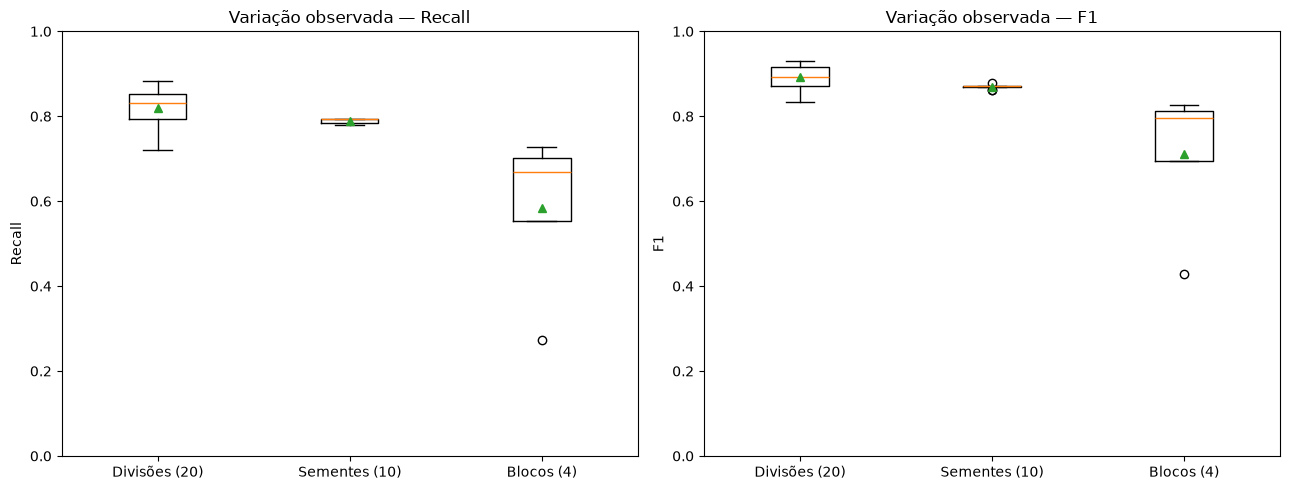

In [52]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
grupos=list(df_estabilidade.Protocolo.unique())
for ax,metrica in zip(axes,["Recall","F1"]):
    ax.boxplot([df_estabilidade.loc[df_estabilidade.Protocolo.eq(g),metrica] for g in grupos],tick_labels=["Divisões (20)","Sementes (10)","Blocos (4)"],showmeans=True)
    ax.set_ylim(0,1)
    ax.set_ylabel(metrica)
    ax.set_title("Variação observada — "+metrica)
plt.tight_layout()
plt.show()

## Leitura da estabilidade

Configuração fixa, sem pesos, Type e três derivadas; teste original excluído de todas as 34 execuções.

| Protocolo | Recall médio ± desvio padrão | Faixa de recall | F1 médio | AP média |
|---|---:|---:|---:|---:|
| 20 divisões aleatórias | 82.0% ± 4.4% | 72.1%–88.2% | 0.891 | 0.906 |
| 10 sementes · dados fixos | 79.0% ± 0.7% | 77.9%–79.4% | 0.870 | 0.870 |
| 4 blocos ordenados | 58.5% ± 21.0% | 27.4%–72.7% | 0.711 | 0.797 |

**Consistente quanto à semente e promissor nas divisões aleatórias, porém sensível à ordem dos dados.** A janela mais difícil (UDI 3.998–5.976) teve 124 falhas, das quais 34 detectadas e 90 perdidas (recall 27,4%). Nessa janela havia 85 ocorrências de HDF na validação e 4 no treino do bloco. Os modos de falha foram consultados apenas para diagnóstico posterior, nunca como entradas. Essa mudança de cobertura ajuda a interpretar a queda, sem provar uma causa única.

Os blocos têm treinos de tamanhos diferentes e prevalências diferentes; sua média é a média simples das quatro janelas e não equivale a um recall agregado. O desempenho em blocos não deve ser comparado como se tivesse o mesmo desenho das divisões aleatórias. A janela inicial treina apenas 1.570 registros, e a mais difícil usa 3.170. O gap de 30 não corresponde a um horizonte temporal real; o UDI não é um histórico completo por equipamento.

O resultado original (recall 79,4%, F1 0,878, AP 0,873) é plausível dentro da variação aleatória observada. Isso sustenta continuar o protótipo, mas não valida a implantação para previsão futura na indústria. As avaliações exploram somente os 8.000 registros de desenvolvimento, após escolhas anteriores de configuração. As 20 divisões compartilham dados: desvio padrão, faixa e percentis não são intervalos de confiança independentes.

O rascunho de interface usa a floresta original da divisão 6.000/2.000, e não um modelo escolhido pelo maior resultado nesta análise. Scores são de classificação, sem calibração. Não foi alterado o limiar de decisão.


# Rodada 5 — Random Oversampling

Mesma divisão e mesmos hiperparâmetros das versões sem pesos da rodada 2, com as três features derivadas. Testamos Random Forest, SVC RBF e XGBoost com e sem Type, preservando os limiares padrão. O encoder e o scaler foram ajustados no treino original. O RandomOverSampler duplica apenas exemplos da classe minoritária do treino até a proporção 1:1, com semente 42. A validação mantém a proporção original de falhas e o teste permanece reservado. As versões com pesos da rodada 2 aparecem como referência separada.


In [53]:
from sklearn.base import clone
from imblearn.over_sampling import RandomOverSampler

sampler_ros = RandomOverSampler(sampling_strategy="minority", random_state=42)
X_train_ros, y_train_ros = sampler_ros.fit_resample(X_train_features, y_train)
origem_ros = X_train_features.index[sampler_ros.sample_indices_]
assert origem_ros.isin(X_train_features.index).all()
assert not origem_ros.isin(X_valid_features.index).any()
assert not origem_ros.isin(X_test.index).any()
assert y_train_ros.value_counts().nunique() == 1
assert len(y_valid) == 2000 and int(y_valid.sum()) == 68
print("Treino original:", y_train.value_counts().sort_index().to_dict())
print("Treino após ROS:", y_train_ros.value_counts().sort_index().to_dict())

linhas_ros = []
modelos_ros = {}
for entradas in ["Com Type", "Sem Type"]:
    usar_type = entradas == "Com Type"
    colunas = numericas_features + (list(nomes_type) if usar_type else [])
    for familia in ["Random Forest", "SVC RBF", "XGBoost"]:
        modelo = clone(modelos_features[(f"{familia} - Unbalanced", entradas)])
        treino, valid = X_train_ros[colunas], X_valid_features[colunas]
        if familia == "SVC RBF":
            treino = preparar_features_svc(X_train_ros, usar_type)
            valid = preparar_features_svc(X_valid_features, usar_type)
        elif familia == "XGBoost":
            treino, valid = treino.to_numpy(), valid.to_numpy()
        modelo.fit(treino, y_train_ros)
        assert getattr(modelo, "fit_status_", 0) == 0, f"Falha de convergência: {familia} {entradas}"
        modelos_ros[(familia, entradas)] = modelo
        pred = modelo.predict(valid)
        score = modelo.decision_function(valid) if familia == "SVC RBF" else modelo.predict_proba(valid)[:, 1]
        tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()
        chave = {"Modelo": familia, "Entradas": entradas}
        linhas_ros.append({**chave, "Estratégia": "Oversampling 1:1",
            "Precisão": precision_score(y_valid, pred, zero_division=0),
            "Recall": recall_score(y_valid, pred), "F1": f1_score(y_valid, pred),
            "AP": average_precision_score(y_valid, score), "Falhas encontradas": tp,
            "Falhas perdidas": fn, "Falsos alarmes": fp})
        for sufixo, estrategia in [("Unbalanced", "Treino original"), ("Balanced", "Pesos de classe")]:
            base = df_resultados_features.loc[
                df_resultados_features.Modelo.eq(f"{familia} - {sufixo}") & df_resultados_features.Entradas.eq(entradas)
            ].iloc[0]
            linhas_ros.append({**chave, "Estratégia": estrategia,
                "Precisão": base["Precision classe 1"], "Recall": base["Recall classe 1"],
                "F1": base["F1 classe 1"], "AP": base["PR-AUC"],
                "Falhas encontradas": 68 - int(base["Falsos Negativos"]),
                "Falhas perdidas": int(base["Falsos Negativos"]), "Falsos alarmes": int(base["Falsos Positivos"])})

comparacao_ros = pd.DataFrame(linhas_ros)
assert len(comparacao_ros) == 18 and not comparacao_ros.duplicated(["Modelo", "Entradas", "Estratégia"]).any()
assert comparacao_ros[["Falhas encontradas", "Falhas perdidas"]].sum(axis=1).eq(68).all()
comparacao_ros


Treino original: {0: 5797, 1: 203}
Treino após ROS: {0: 5797, 1: 5797}


,Modelo,Entradas,Estratégia,Precisão,Recall,F1,AP,Falhas encontradas,Falhas perdidas,Falsos alarmes
0,Random Forest,Com Type,Oversampling 1:1,0.800000,0.764706,0.781955,0.843701,52,16,13
1,Random Forest,Com Type,Treino original,0.981818,0.794118,0.878049,0.873354,54,14,1
2,Random Forest,Com Type,Pesos de classe,0.746479,0.779412,0.762590,0.841901,53,15,18
3,SVC RBF,Com Type,Oversampling 1:1,0.296651,0.911765,0.447653,0.643134,62,6,147
4,SVC RBF,Com Type,Treino original,0.857143,0.264706,0.404494,0.687479,18,50,3
5,SVC RBF,Com Type,Pesos de classe,0.311224,0.897059,0.462121,0.578419,61,7,135
6,XGBoost,Com Type,Oversampling 1:1,0.575758,0.838235,0.682635,0.870752,57,11,42
7,XGBoost,Com Type,Treino original,0.883333,0.779412,0.828125,0.849798,53,15,7
8,XGBoost,Com Type,Pesos de classe,0.587629,0.838235,0.690909,0.811829,57,11,40
9,Random Forest,Sem Type,Oversampling 1:1,0.753623,0.764706,0.759124,0.837799,52,16,17


## Tabelas completas da validação

In [54]:
from IPython.display import display

estrategias_ros = ["Treino original", "Pesos de classe", "Oversampling 1:1"]
colunas_ros = ["Modelo", "Estratégia", "Falhas encontradas", "Falhas perdidas",
               "Falsos alarmes", "Precisão", "Recall", "F1", "AP"]
for variante in ["Com Type", "Sem Type"]:
    print(f"{variante} — validação: 2.000 registros, 68 falhas")
    tabela = comparacao_ros.loc[comparacao_ros["Entradas"].eq(variante), colunas_ros].copy()
    tabela["Estratégia"] = pd.Categorical(tabela["Estratégia"], estrategias_ros, ordered=True)
    tabela = tabela.sort_values(["Modelo", "Estratégia"])
    for coluna in ["Precisão", "Recall"]:
        tabela[coluna] = tabela[coluna].map(lambda v: f"{v:.1%}")
    tabela[["F1", "AP"]] = tabela[["F1", "AP"]].round(3)
    display(tabela.reset_index(drop=True))


Com Type — validação: 2.000 registros, 68 falhas


Modelo,Estratégia,Falhas encontradas,Falhas perdidas,Falsos alarmes,Precisão,Recall,F1,AP
Random Forest,Treino original,54,14,1,98.2%,79.4%,0.878,0.873
Random Forest,Pesos de classe,53,15,18,74.6%,77.9%,0.763,0.842
Random Forest,Oversampling 1:1,52,16,13,80.0%,76.5%,0.782,0.844
SVC RBF,Treino original,18,50,3,85.7%,26.5%,0.404,0.687
SVC RBF,Pesos de classe,61,7,135,31.1%,89.7%,0.462,0.578
SVC RBF,Oversampling 1:1,62,6,147,29.7%,91.2%,0.448,0.643
XGBoost,Treino original,53,15,7,88.3%,77.9%,0.828,0.850
XGBoost,Pesos de classe,57,11,40,58.8%,83.8%,0.691,0.812
XGBoost,Oversampling 1:1,57,11,42,57.6%,83.8%,0.683,0.871


Sem Type — validação: 2.000 registros, 68 falhas


Modelo,Estratégia,Falhas encontradas,Falhas perdidas,Falsos alarmes,Precisão,Recall,F1,AP
Random Forest,Treino original,52,16,3,94.5%,76.5%,0.846,0.868
Random Forest,Pesos de classe,54,14,19,74.0%,79.4%,0.766,0.839
Random Forest,Oversampling 1:1,52,16,17,75.4%,76.5%,0.759,0.838
SVC RBF,Treino original,20,48,3,87.0%,29.4%,0.440,0.713
SVC RBF,Pesos de classe,61,7,141,30.2%,89.7%,0.452,0.572
SVC RBF,Oversampling 1:1,64,4,158,28.8%,94.1%,0.441,0.664
XGBoost,Treino original,52,16,6,89.7%,76.5%,0.825,0.840
XGBoost,Pesos de classe,57,11,40,58.8%,83.8%,0.691,0.802
XGBoost,Oversampling 1:1,58,10,36,61.7%,85.3%,0.716,0.875


## Gráficos comparativos da rodada 5

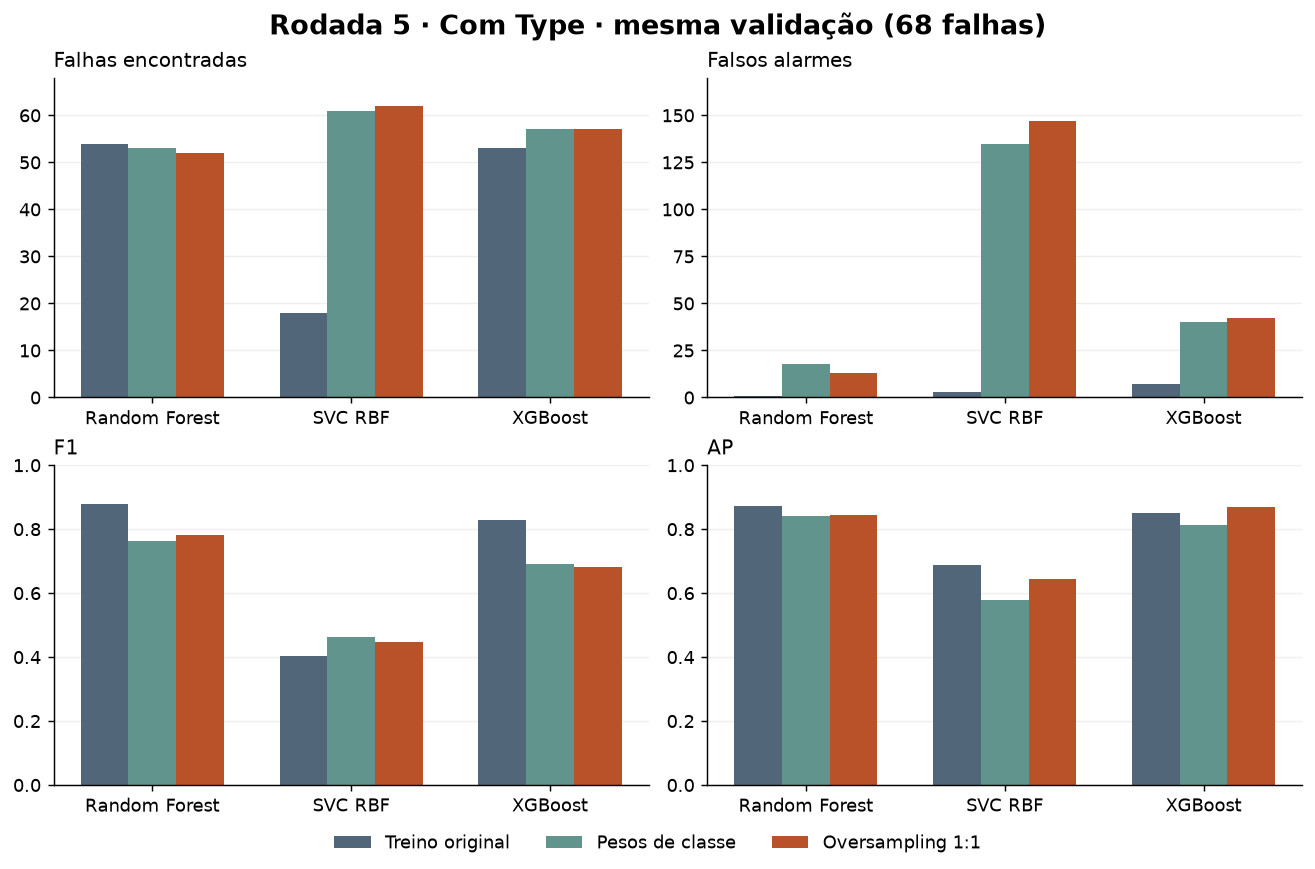

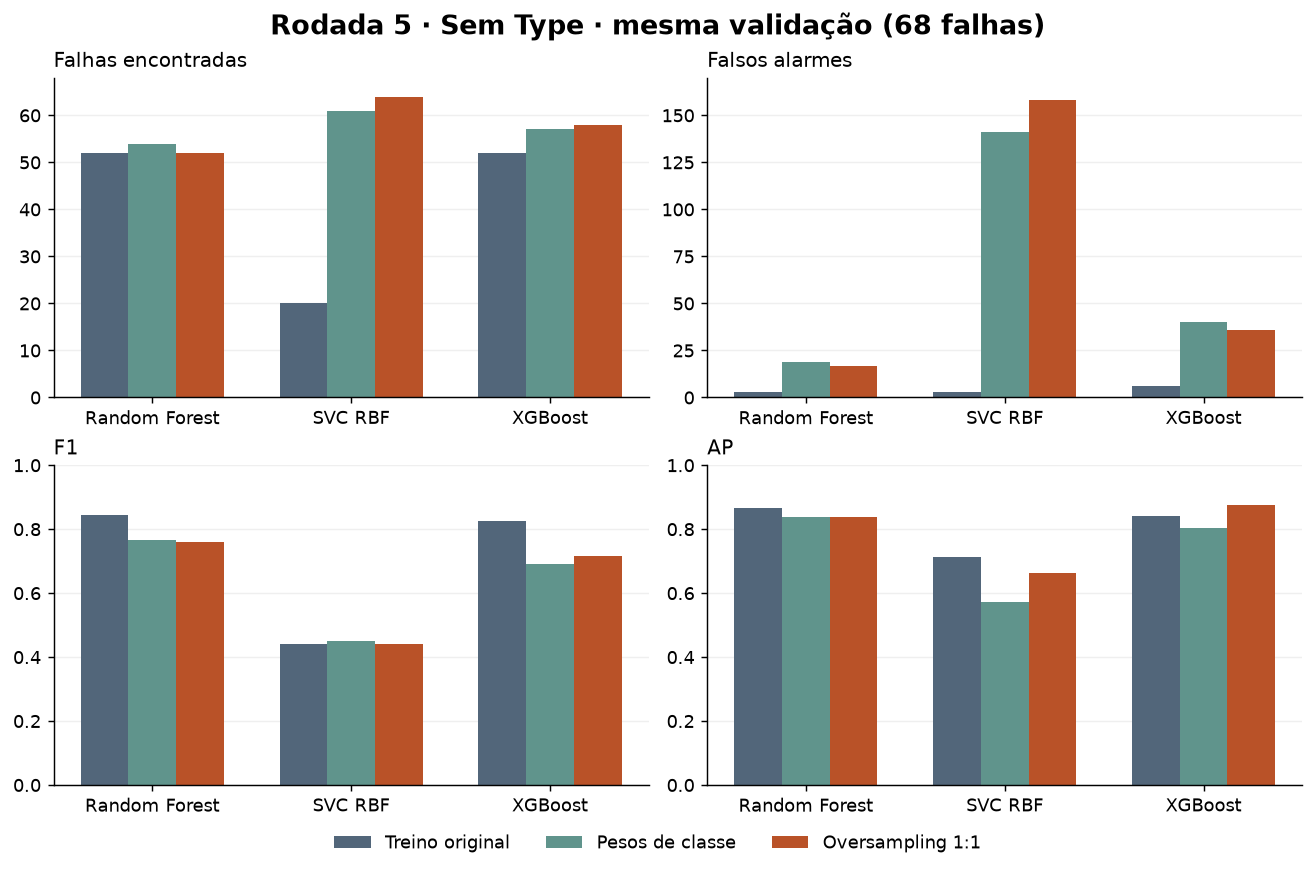

In [55]:
import matplotlib.pyplot as plt
import numpy as np

familias_ros = ["Random Forest", "SVC RBF", "XGBoost"]
cores_ros = ["#52667a", "#60948c", "#b95228"]
metricas_ros = ["Falhas encontradas", "Falsos alarmes", "F1", "AP"]

for variante in ["Com Type", "Sem Type"]:
    fig, eixos = plt.subplots(2, 2, figsize=(10, 6.6), layout="constrained")
    fig.suptitle(f"Rodada 5 · {variante} · mesma validação (68 falhas)", fontsize=15, fontweight="bold")
    quadro = comparacao_ros[comparacao_ros["Entradas"].eq(variante)]
    posicoes = np.arange(len(familias_ros))
    largura = 0.24
    for ax, metrica in zip(eixos.flat, metricas_ros):
        valores = quadro.pivot(index="Modelo", columns="Estratégia", values=metrica)
        valores = valores.reindex(index=familias_ros, columns=estrategias_ros)
        for i, (estrategia, cor) in enumerate(zip(estrategias_ros, cores_ros)):
            ax.bar(posicoes + (i - 1) * largura, valores[estrategia], largura, color=cor, label=estrategia)
        ax.set_title(metrica, loc="left", fontsize=11)
        ax.set_xticks(posicoes, familias_ros)
        ax.set_ylim(0, {"Falhas encontradas": 68, "Falsos alarmes": 170, "F1": 1, "AP": 1}[metrica])
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    handles, labels = eixos[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
    display(fig)
    plt.close(fig)


## Rodada 6 corrigida — validação cruzada repetida e ablação

O conjunto de desenvolvimento reúne **treino e validação da divisão original** (8.000 registros e 271 falhas). A divisão original é reproduzida em duas etapas e os índices são verificados. A versão anterior desta rodada separava 20% diretamente, o que levou 992 registros do teste original ao desenvolvimento.

- **Fold:** uma das cinco partes do desenvolvimento. Cada avaliação treina em quatro partes (6.400 registros) e valida na quinta (1.600).
- **Estratificação:** mantém proporções de falha semelhantes nas cinco partes. Há 54 ou 55 falhas em cada fold de validação.
- **Repetição:** faz três sorteios completos de cinco partes. Cada registro recebe uma previsão fora do treino por repetição, em 15 avaliações por configuração. Os mesmos folds são reutilizados entre configurações.
- **Oversampling:** duplica exemplos da classe minoritária somente no treino do fold.
- **Ablação:** remove ou isola uma variável para medir a diferença de desempenho.
- **AP, precisão, recall e F1:** AP resume a ordenação dos scores ao longo dos limiares. Precisão é a fração dos alertas que são falhas. Recall é a fração das falhas encontradas. F1 combina precisão e recall pela média harmônica. As classes usam o limiar padrão da RF, com score acima de 0,5 para classe positiva.
- **F1_max:** melhor F1 no próprio fold de validação, um teto retrospectivo. A seleção de um limiar para uso real requer validação interna.
- **Desvio padrão:** descreve a variação entre folds. Os dados são reutilizados, portanto os folds não constituem 15 observações independentes.


In [56]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix
from imblearn.over_sampling import RandomOverSampler

df6 = pd.read_csv("ai4i2020.csv")
y6 = df6["Machine failure"]
X6 = df6.rename(columns={"Air temperature [K]":"air","Process temperature [K]":"proc","Rotational speed [rpm]":"rpm",
                         "Torque [Nm]":"torque","Tool wear [min]":"wear"})[["Type","air","proc","rpm","torque","wear"]].copy()
X6["temp_diff"] = X6.proc - X6.air
X6["power_w"] = X6.torque * X6.rpm * 2*np.pi/60
X6["wear_x_torque"] = X6.wear * X6.torque
for t in "LMH": X6["Type_"+t] = (X6.Type == t).astype(int)
X6 = X6.drop(columns="Type")

# Reproduz exatamente a separação original da célula de treino/validação/teste.
idx_treino6, idx_temp6 = train_test_split(
    df6.index, test_size=0.4, stratify=y6, random_state=42
)
idx_valid6, idx_teste6 = train_test_split(
    idx_temp6, test_size=0.5, stratify=y6.loc[idx_temp6], random_state=42
)
idx_dev6 = idx_treino6.union(idx_valid6, sort=True)
assert len(idx_dev6) == 8000 and len(idx_teste6) == 2000
assert idx_dev6.intersection(idx_teste6).empty
X_dev6, y_dev6 = X6.loc[idx_dev6].copy(), y6.loc[idx_dev6].copy()
assert int(y_dev6.sum()) == 271
if "X_test" in globals():
    assert set(idx_teste6) == set(X_test.index)
    assert set(idx_dev6) == set(X_train.index) | set(X_valid.index)
print(f"Desenvolvimento: {len(idx_dev6)} registros, {int(y_dev6.sum())} falhas")
print(f"Sobreposição com teste original: {len(idx_dev6.intersection(idx_teste6))} registros")

base6 = ["air","proc","rpm","torque","wear","Type_L","Type_M","Type_H"]
deriv6 = ["temp_diff","power_w","wear_x_torque"]
cv6 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)

folds6 = list(cv6.split(X_dev6, y_dev6))
assert len(folds6) == 15
for repeticao in range(3):
    partes = folds6[repeticao * 5:(repeticao + 1) * 5]
    assert np.array_equal(np.sort(np.concatenate([va for _, va in partes])), np.arange(8000))
for tr, va in folds6:
    assert len(tr) == 6400 and len(va) == 1600
    assert np.intersect1d(tr, va).size == 0
    assert X_dev6.index[tr].intersection(idx_teste6).empty
    assert X_dev6.index[va].intersection(idx_teste6).empty

def rf6(cw=None):
    return RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1, class_weight=cw)

def rodar_cv(colunas, cw=None, ros=False):
    linhas = []
    for tr, va in folds6:
        a, b = X_dev6.iloc[tr][colunas], X_dev6.iloc[va][colunas]
        ya, yb = y_dev6.iloc[tr], y_dev6.iloc[va]
        if ros:
            a, ya = RandomOverSampler(random_state=42).fit_resample(a, ya)
        p = rf6(cw).fit(a, ya).predict_proba(b)[:, 1]
        tn, fp, fn, tp = confusion_matrix(yb, (p > .5).astype(int), labels=[0,1]).ravel()
        P, R, _ = precision_recall_curve(yb, p)
        linhas.append(dict(AP=average_precision_score(yb, p), Recall=tp/(tp+fn), Precisao=tp/max(tp+fp,1),
                           F1=2*tp/(2*tp+fp+fn), F1_max=(2*P*R/np.maximum(P+R,1e-9)).max(), FN=fn, FP=fp))
    return pd.DataFrame(linhas)

def resumo(nome, d):
    r = {"Configuração": nome}
    for k in ["AP","Recall","Precisao","F1","F1_max","FN","FP"]: r[k] = d[k].mean()
    r["AP (dp)"], r["F1 (dp)"], r["Recall (dp)"] = d.AP.std(), d.F1.std(), d.Recall.std()
    return r

Desenvolvimento: 8000 registros, 271 falhas
Sobreposição com teste original: 0 registros


### 6a. Balanceamento: RF sem pesos × com pesos × oversampling (11 features, 15 folds)
`F1_max` é o F1 com o limiar ótimo em cada fold, só como teto de comparação (não é uma escolha honesta de limiar).

In [57]:
configs6 = [("RF sem pesos", None, False), ("RF balanced", "balanced", False),
            ("RF balanced_subsample", "balanced_subsample", False), ("RF + ROS", None, True)]
brutos6 = {n: rodar_cv(base6 + deriv6, cw, ros) for n, cw, ros in configs6}
tab_bal6 = pd.DataFrame([resumo(n, d) for n, d in brutos6.items()]).set_index("Configuração")
tab_bal6.round(3)

,AP,Recall,Precisao,F1,F1_max,FN,FP,AP (dp),F1 (dp),Recall (dp)
Configuração,,,,,,,,,,
RF sem pesos,0.898,0.808,0.970,0.881,0.891,10.400,1.400,0.024,0.030,0.046
RF balanced,0.885,0.829,0.729,0.774,0.862,9.267,17.267,0.027,0.044,0.043
RF balanced_subsample,0.891,0.781,0.966,0.863,0.880,11.867,1.533,0.024,0.033,0.054
RF + ROS,0.885,0.822,0.787,0.801,0.857,9.667,12.733,0.029,0.048,0.042


### 6b. Diferença pareada em relação à RF sem pesos (mesmos folds)

In [58]:
ref6 = brutos6["RF sem pesos"]
linhas = []
for n in ["RF balanced", "RF balanced_subsample", "RF + ROS"]:
    for k in ["AP", "F1", "Recall"]:
        dd = brutos6[n][k] - ref6[k]
        linhas.append({"Configuração": n, "Métrica": k, "Dif. média": dd.mean(),
                       "Desvio das diferenças": dd.std(), "Folds melhores que a ref.": f"{(dd>0).sum()}/{len(dd)}"})
pd.DataFrame(linhas).round(4)

,Configuração,Métrica,Dif. média,Desvio das diferenças,Folds melhores que a ref.
0,RF balanced,AP,-0.0130,0.0122,2/15
1,RF balanced,F1,-0.1072,0.0481,0/15
2,RF balanced,Recall,0.0210,0.0334,9/15
3,RF balanced_subsample,AP,-0.0066,0.0080,3/15
4,RF balanced_subsample,F1,-0.0181,0.0216,2/15
5,RF balanced_subsample,Recall,-0.0270,0.0310,3/15
6,RF + ROS,AP,-0.0130,0.0140,3/15
7,RF + ROS,F1,-0.0797,0.0453,0/15
8,RF + ROS,Recall,0.0136,0.0366,7/15


### 6c. Ablação das features derivadas (RF sem pesos)

In [59]:
conj6 = {"sem derivadas": base6, "só temp_diff": base6 + ["temp_diff"], "só power_w": base6 + ["power_w"],
         "só wear_x_torque": base6 + ["wear_x_torque"]}
for d_ in deriv6:
    conj6["todas menos " + d_] = base6 + [x for x in deriv6 if x != d_]
conj6["sem Type, todas as derivadas"] = [c for c in base6 + deriv6 if not c.startswith("Type_")]
conj6["todas (referência)"] = base6 + deriv6
tab_abl6 = pd.DataFrame([resumo(n, rodar_cv(c)) for n, c in conj6.items()]).set_index("Configuração")
tab_abl6.round(3)

,AP,Recall,Precisao,F1,F1_max,FN,FP,AP (dp),F1 (dp),Recall (dp)
Configuração,,,,,,,,,,
sem derivadas,0.777,0.444,0.890,0.589,0.752,30.133,2.933,0.060,0.085,0.085
só temp_diff,0.842,0.645,0.930,0.760,0.806,19.267,2.667,0.045,0.055,0.066
só power_w,0.835,0.559,0.949,0.701,0.797,23.933,1.667,0.040,0.054,0.062
só wear_x_torque,0.823,0.605,0.915,0.726,0.803,21.400,3.067,0.044,0.061,0.074
todas menos temp_diff,0.859,0.627,0.964,0.759,0.828,20.200,1.267,0.032,0.051,0.063
todas menos power_w,0.863,0.742,0.939,0.828,0.851,14.000,2.600,0.039,0.042,0.056
todas menos wear_x_torque,0.880,0.702,0.966,0.812,0.842,16.133,1.333,0.030,0.045,0.057
"sem Type, todas as derivadas",0.882,0.804,0.921,0.858,0.873,10.600,3.800,0.032,0.031,0.047
todas (referência),0.898,0.808,0.970,0.881,0.891,10.400,1.400,0.024,0.030,0.046


In [60]:
imp6 = pd.Series(rf6().fit(X_dev6[base6 + deriv6], y_dev6).feature_importances_, base6 + deriv6).sort_values(ascending=False)
imp6.round(3).to_frame("Importância (RF sem pesos, desenvolvimento)")

,"Importância (RF sem pesos, desenvolvimento)"
wear_x_torque,0.223
power_w,0.215
rpm,0.163
torque,0.135
temp_diff,0.114
wear,0.056
air,0.035
proc,0.030
Type_L,0.014
Type_M,0.012


### Resultados da rodada corrigida

- **RF sem pesos:** AP 0,898, F1 0,881, recall 80,8%, precisão 97,0% e 1,400 falso(s) alarme(s) por fold, em média.
- **Ablação:** o recall passou de 44,4% sem derivadas para 80,8% com as três. A AP com e sem Type foi 0,898 e 0,882, respectivamente.
- A análise é estratificada e aleatória. O desempenho por blocos ordenados é uma questão separada. O teste original ficou fora desta reexecução, mas os 992 registros já usados na versão anterior não recuperam a independência. Registre essa exposição ao definir a avaliação final.


### Gráficos da rodada 6

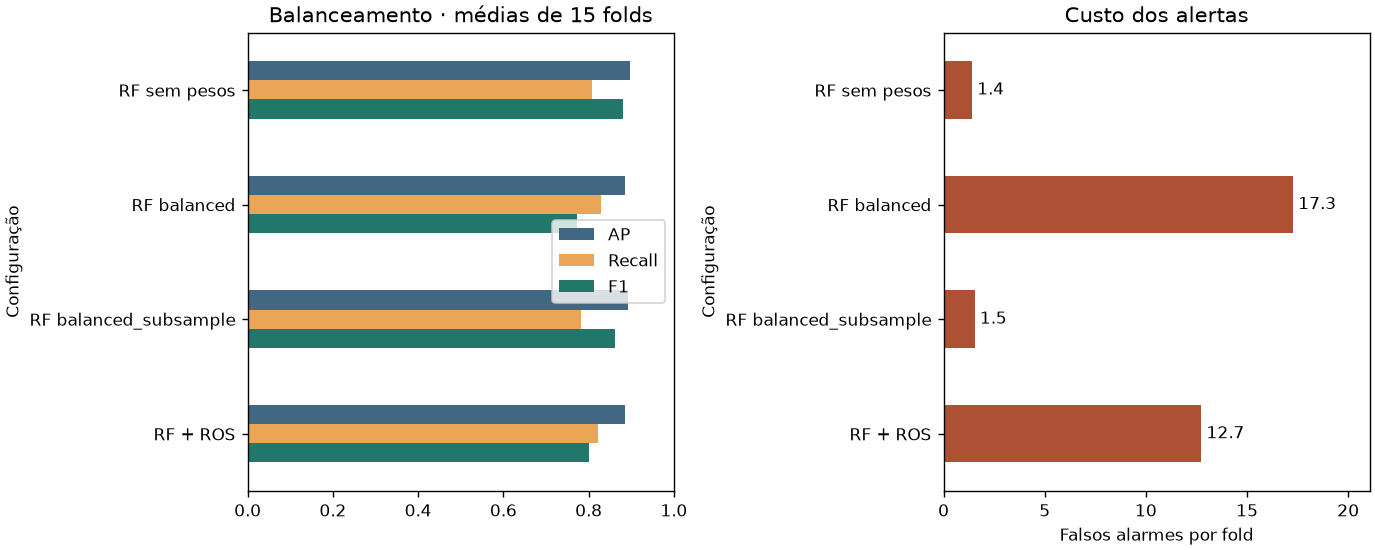

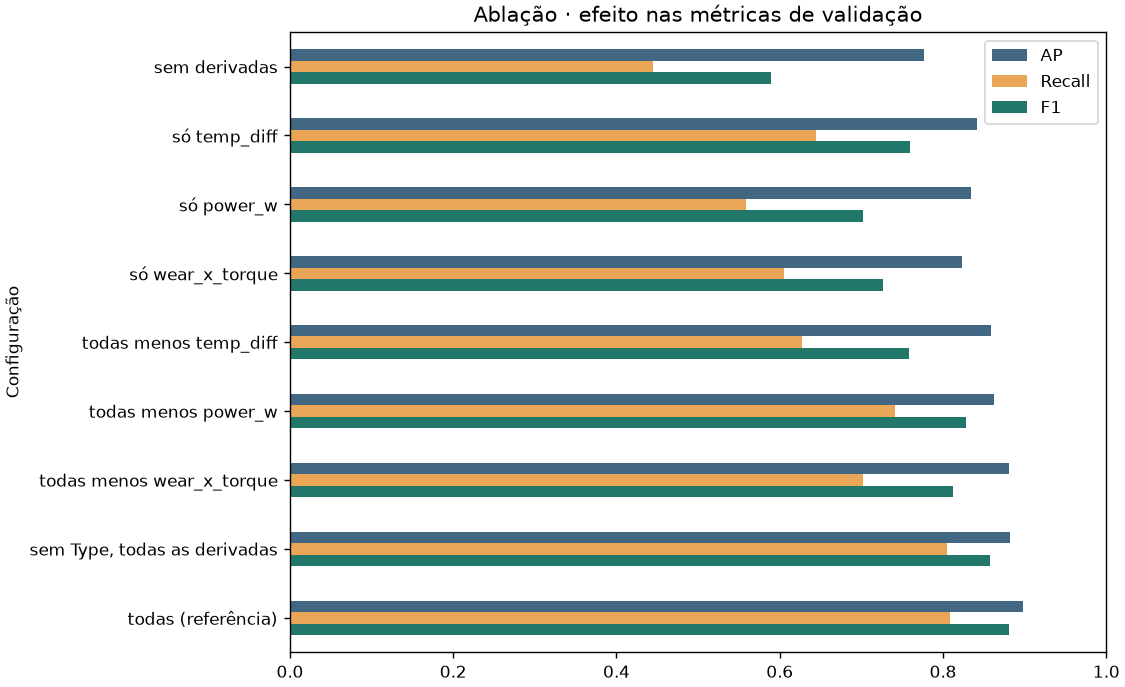

In [62]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
tab_bal6[["AP", "Recall", "F1"]].plot.barh(ax=axes[0], color=["#416783", "#eaa556", "#217769"])
axes[0].set(xlim=(0, 1), title="Balanceamento · médias de 15 folds")
axes[0].invert_yaxis()
tab_bal6["FP"].plot.barh(ax=axes[1], color="#ad5034")
axes[1].set(xlabel="Falsos alarmes por fold", title="Custo dos alertas")
axes[1].invert_yaxis()
axes[1].bar_label(axes[1].containers[0], fmt="%.1f", padding=3)
axes[1].set_xlim(0, tab_bal6["FP"].max() * 1.22)
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
tab_abl6[["AP", "Recall", "F1"]].plot.barh(ax=ax, color=["#416783", "#eaa556", "#217769"])
ax.set(xlim=(0, 1), title="Ablação · efeito nas métricas de validação")
ax.invert_yaxis()
display(fig)
plt.close(fig)

## Rodada 7 — decisão de alerta da Random Forest

A Random Forest sem pesos é treinada com as 11 features da rodada 6. Seu score é a média das estimativas da classe positiva produzidas pelas árvores. A regra padrão alerta quando o score é maior que 0,50. Uma regra mais sensível usa um corte menor, mantendo o mesmo modelo e os mesmos scores para a comparação externa.

Usamos os 15 folds externos da rodada 6. Em cada treino externo, uma validação cruzada interna estratificada de três folds gera scores para escolher o limiar. Avaliamos os cortes de 0,05 a 0,50 em passos de 0,025. O critério, definido antes da execução, é detectar o máximo de falhas com até 5 falsos alarmes adicionais por 1.000 registros internos em relação a 0,50. Empates favorecem menos falsos alarmes e depois o maior corte. O orçamento é experimental e vale para a seleção interna. O resultado externo pode ultrapassá-lo.

Depois de escolhido o corte, treinamos uma floresta em todo o treino externo e aplicamos os dois limiares sobre os mesmos scores do fold externo. A marca TWF serve apenas para contar falhas por desgaste entre os registros positivos. O teste reservado fica fora. As repetições reutilizam registros, então as médias e os totais por repetição são descritivos.

In [64]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cortes7 = np.arange(2, 21) / 40
limite_extra_por_mil7 = 5
X7 = X_dev6[base6 + deriv6]
y7 = y_dev6
twf7 = df6.loc[X7.index, "TWF"].eq(1) & y7.eq(1)
registros7 = []

def contagens7(verdade, scores, corte, twf):
    alerta = scores > corte
    vp = int(np.count_nonzero(alerta & verdade))
    fp = int(np.count_nonzero(alerta & ~verdade))
    return {"VP": vp, "FP": fp, "FN": int(verdade.sum()) - vp,
            "Alertas": vp + fp, "TWF detectadas": int(np.count_nonzero(alerta & twf))}

for i, (tr, va) in enumerate(folds6):
    assert X7.index[tr].intersection(idx_teste6).empty
    assert X7.index[va].intersection(idx_teste6).empty
    Xtr, ytr = X7.iloc[tr], y7.iloc[tr]
    interna = StratifiedKFold(n_splits=3, shuffle=True, random_state=1700 + i)
    p_interno = cross_val_predict(rf6(), Xtr, ytr, cv=interna, method="predict_proba")[:, 1]
    verdade_interna = ytr.to_numpy(dtype=bool)
    negativos = ~verdade_interna
    fp_padrao = int(np.count_nonzero((p_interno > 0.5) & negativos))
    candidatos = []
    for corte in cortes7:
        alertas = p_interno > corte
        fp = int(np.count_nonzero(alertas & negativos))
        if 1000 * (fp - fp_padrao) <= limite_extra_por_mil7 * len(tr):
            vp = int(np.count_nonzero(alertas & verdade_interna))
            candidatos.append((vp, -fp, corte))
    corte = max(candidatos)[2]
    assert corte <= 0.5

    p_externo = rf6().fit(Xtr, ytr).predict_proba(X7.iloc[va])[:, 1]
    verdade = y7.iloc[va].to_numpy(dtype=bool)
    twf = twf7.iloc[va].to_numpy(dtype=bool)
    for politica, t in [("Padrão", 0.5), ("Mais sensível", corte)]:
        registros7.append({"Repetição": i // 5 + 1, "Fold": i % 5 + 1,
                           "Política": politica, "Limiar": t, "Registros": len(va),
                           "Falhas reais": int(verdade.sum()), "TWF reais": int(twf.sum()),
                           **contagens7(verdade, p_externo, t, twf)})

detalhes7 = pd.DataFrame(registros7)
assert len(detalhes7) == 30
assert detalhes7.groupby(["Repetição", "Política"])["Falhas reais"].sum().eq(271).all()
delta7 = detalhes7[detalhes7["Política"].eq("Mais sensível")].set_index(["Repetição","Fold"])
padrao7 = detalhes7[detalhes7["Política"].eq("Padrão")].set_index(["Repetição","Fold"])
contagens_col7 = ["VP", "FP", "FN", "Alertas", "TWF detectadas", "TWF reais"]
ganhos7 = delta7[contagens_col7] - padrao7[contagens_col7]
assert ganhos7[["VP", "FP", "Alertas", "TWF detectadas"]].ge(0).all().all()
assert padrao7["FP"].mean() == tab_bal6.loc["RF sem pesos", "FP"]
repeticoes7 = detalhes7.groupby(["Repetição", "Política"])[contagens_col7].sum()
repeticoes7["Recall geral"] = repeticoes7["VP"] / (repeticoes7["VP"] + repeticoes7["FN"])
repeticoes7["Precisão"] = repeticoes7["VP"] / repeticoes7["Alertas"]
repeticoes7["Recall TWF"] = repeticoes7["TWF detectadas"] / repeticoes7["TWF reais"]
resumo7 = detalhes7.groupby("Política")[contagens_col7].mean()
display(resumo7.round(2))
display(repeticoes7.round(3))
display(ganhos7.groupby(level="Repetição").sum())
display(detalhes7[["Repetição", "Fold", "Política", "Limiar", "VP", "FP", "TWF detectadas"]])


,VP,FP,FN,Alertas,TWF detectadas,TWF reais
Política,,,,,,
Mais sensível,45.47,7.27,8.73,52.73,0.80,7.8
Padrão,43.80,1.40,10.40,45.20,0.53,7.8


VP  FP  FN  Alertas  TWF detectadas  TWF reais  Recall geral  Precisão  Recall TWF
Repetição Política                                                                                          
1         Mais sensível  228  33  43      261               4         39         0.841     0.874       0.103
          Padrão         219   8  52      227               3         39         0.808     0.965       0.077
2         Mais sensível  227  40  44      267               4         39         0.838     0.850       0.103
          Padrão         220   7  51      227               2         39         0.812     0.969       0.051
3         Mais sensível  227  36  44      263               4         39         0.838     0.863       0.103
          Padrão         218   6  53      224               3         39         0.804     0.973       0.077

,VP,FP,FN,Alertas,TWF detectadas,TWF reais
Repetição,,,,,,
1,9,25,-9,34,1,0
2,7,33,-7,40,2,0
3,9,30,-9,39,1,0


,Repetição,Fold,Política,Limiar,VP,FP,TWF detectadas
0,1,1,Padrão,0.500,43,1,1
1,1,1,Mais sensível,0.250,46,5,2
2,1,2,Padrão,0.500,43,3,1
3,1,2,Mais sensível,0.250,44,10,1
4,1,3,Padrão,0.500,47,0,0
5,1,3,Mais sensível,0.275,48,6,0
6,1,4,Padrão,0.500,40,1,0
7,1,4,Mais sensível,0.250,43,7,0
8,1,5,Padrão,0.500,46,3,1
9,1,5,Mais sensível,0.375,47,5,1


### Gráficos da rodada 7

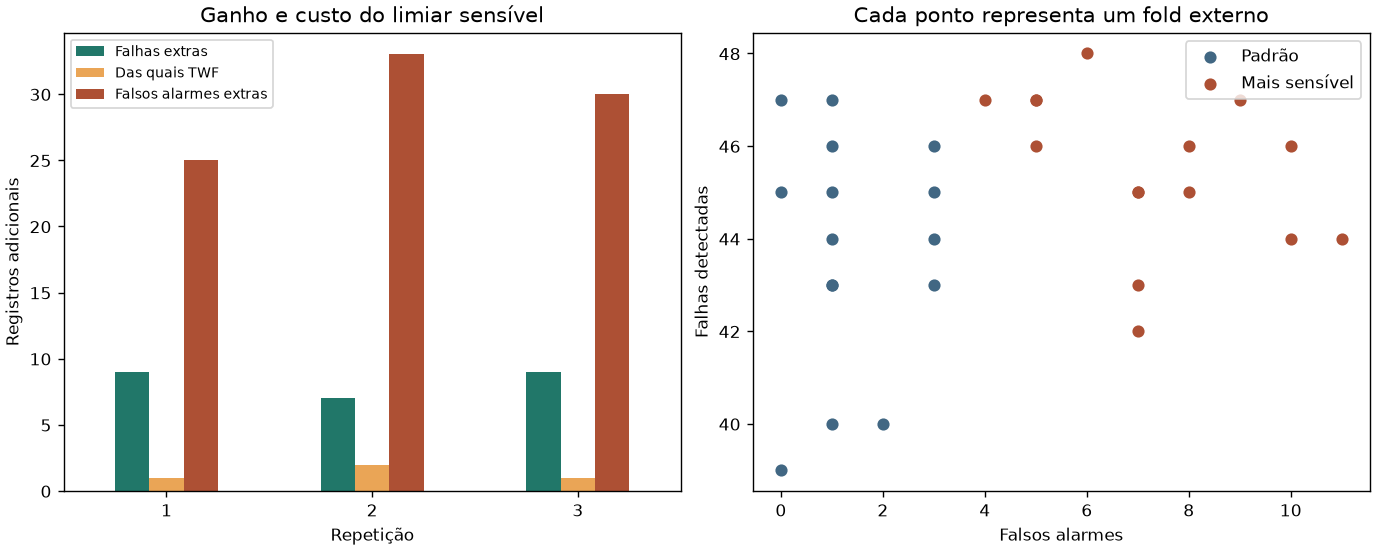

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
ganhos7.groupby(level="Repetição")[["VP", "TWF detectadas", "FP"]].sum().rename(
    columns={"VP": "Falhas extras", "TWF detectadas": "Das quais TWF", "FP": "Falsos alarmes extras"}
).plot.bar(ax=axes[0], color=["#217769", "#eaa556", "#ad5034"], rot=0)
axes[0].set(title="Ganho e custo do limiar sensível", ylabel="Registros adicionais")
axes[0].legend(fontsize=8)
axes[1].scatter(padrao7["FP"], padrao7["VP"], label="Padrão", color="#416783")
axes[1].scatter(delta7["FP"], delta7["VP"], label="Mais sensível", color="#ad5034")
axes[1].set(title="Cada ponto representa um fold externo", xlabel="Falsos alarmes", ylabel="Falhas detectadas")
axes[1].legend()
display(fig)
plt.close(fig)

### Resultado da política mais sensível

Em média por fold externo, a política recuperou 1.67 falhas adicionais, das quais 0.27 eram TWF. Gerou 5.87 falsos alarmes extras e 7.53 alertas extras ao todo. As tabelas mostram os resultados de cada repetição. Este é um experimento com um orçamento de inspeções assumido, ainda sem fixar o limiar de operação do protótipo.

## Rodada 8 — SMOTENC com treino e validação separados

Comparamos RF sem pesos, RF com ROS e RF com SMOTENC. Mantemos 200 árvores, profundidade máxima 10, semente 42 e as 11 entradas da floresta de referência. ROS e SMOTENC usam proporção 1:1 entre as classes. O SMOTENC usa cinco vizinhos.

A divisão original de 6.000 registros de treino, 2.000 de validação e 2.000 de teste é reproduzida em duas etapas. Os cinco folds internos, estratificados e idênticos para as três configurações, pertencem exclusivamente ao treino de 6.000 registros. A escala do SMOTENC é ajustada nos registros de treino de cada fold. As linhas sintéticas são criadas nas cinco medições brutas, com Type tratada como categoria. Depois da volta à escala original, potência, diferença de temperatura e desgaste × torque são recalculados. Os folds avaliados usam registros originais.

Para cada modelo, comparamos o corte padrão de 0,50 com um corte escolhido exclusivamente pelos scores fora do treino dos cinco folds internos. Usamos o mesmo orçamento de falsos alarmes para todos: o total da RF padrão no treino mais cinco por mil registros. Entre os cortes de 0 a 1 em passos de 0,025, a regra maximiza falhas detectadas. Empates favorecem menos falsos alarmes e depois o corte mais alto. O orçamento é experimental e os resultados observados na validação podem divergir dele.

Com os cortes já fixados, reestimamos cada modelo usando os 6.000 registros de treino e avaliamos nos mesmos 2.000 registros da validação original, que já foi usada em rodadas anteriores. TWF é consultada após a previsão para auditar casos de desgaste. Os índices do teste servem para checar a separação.

In [67]:
from IPython.display import display
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, confusion_matrix
from imblearn.over_sampling import RandomOverSampler, SMOTENC

dados8 = pd.read_csv("ai4i2020.csv")
alvo8 = dados8["Machine failure"]
idx_train8, idx_temp8 = train_test_split(
    dados8.index, test_size=0.4, stratify=alvo8, random_state=42
)
idx_valid8, idx_test8 = train_test_split(
    idx_temp8, test_size=0.5, stratify=alvo8.loc[idx_temp8], random_state=42
)
assert (len(idx_train8), len(idx_valid8), len(idx_test8)) == (6000, 2000, 2000)
assert idx_train8.intersection(idx_valid8).empty
assert idx_train8.intersection(idx_test8).empty and idx_valid8.intersection(idx_test8).empty
if "X_train" in globals() and "X_test" in globals():
    assert list(idx_train8) == list(X_train.index)
    assert list(idx_valid8) == list(X_valid.index)
    assert list(idx_test8) == list(X_test.index)

nomes_brutos8 = {
    "Air temperature [K]": "air", "Process temperature [K]": "proc",
    "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque", "Tool wear [min]": "wear"
}
numericas8 = list(nomes_brutos8.values())
estrategias8 = ["Sem reamostragem", "ROS", "SMOTENC"]

def brutas8(indices):
    return dados8.loc[indices, list(nomes_brutos8) + ["Type"]].rename(columns=nomes_brutos8)

def features8(brutas):
    x = brutas[numericas8].copy()
    x["temp_diff"] = x["proc"] - x["air"]
    x["power_w"] = x["torque"] * x["rpm"] * (2 * np.pi / 60)
    x["wear_x_torque"] = x["wear"] * x["torque"]
    for categoria in "HLM":
        x["Type_" + categoria] = brutas["Type"].eq(categoria).astype(int)
    return x

auditoria8 = []

def treinar8(indices, estrategia, etapa):
    assert len(indices) == len(set(indices))
    assert set(indices).issubset(idx_train8)
    assert indices.intersection(idx_valid8).empty and indices.intersection(idx_test8).empty
    x, y = brutas8(indices).reset_index(drop=True), alvo8.loc[indices].reset_index(drop=True)
    contagem_original = y.value_counts()
    if estrategia == "ROS":
        ros = RandomOverSampler(sampling_strategy=1.0, random_state=42)
        x, y = ros.fit_resample(x, y)
        assert np.max(ros.sample_indices_) < len(indices)
    elif estrategia == "SMOTENC":
        escala = StandardScaler()
        x_escalado = x.copy()
        x_escalado[numericas8] = escala.fit_transform(x[numericas8])
        smote = SMOTENC(categorical_features=["Type"], sampling_strategy=1.0,
                        k_neighbors=5, random_state=42)
        x_sint, y = smote.fit_resample(x_escalado, y)
        geradas = x_sint.iloc[len(x):].copy()
        geradas[numericas8] = escala.inverse_transform(geradas[numericas8])
        assert geradas["Type"].isin(x["Type"].unique()).all()
        x = pd.concat([x, geradas], ignore_index=True)
    x = features8(x)
    assert np.isfinite(x.to_numpy()).all()
    if estrategia != "Sem reamostragem":
        assert y.value_counts().to_dict() == {0: int(contagem_original[0]), 1: int(contagem_original[0])}
        assert y.iloc[len(indices):].eq(1).all()
    auditoria8.append({
        "Etapa": etapa, "Estratégia": estrategia, "Linhas originais": len(indices),
        "Falhas originais": int(contagem_original[1]), "Linhas após preparo": len(y),
        "Falhas após preparo": int(y.sum())
    })
    return RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42,
                                  class_weight=None, n_jobs=4).fit(x, y)

y_train8 = alvo8.loc[idx_train8].to_numpy(dtype=bool)
assert y_train8.sum() == 203
cv8 = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(idx_train8, y_train8))
assert np.array_equal(np.sort(np.concatenate([va for _, va in cv8])), np.arange(len(idx_train8)))
scores_internos8 = {nome: np.full(len(idx_train8), np.nan) for nome in estrategias8}
for fold, (tr, va) in enumerate(cv8, start=1):
    ids_tr, ids_va = idx_train8[tr], idx_train8[va]
    assert ids_tr.intersection(ids_va).empty
    assert ids_va.intersection(idx_valid8).empty and ids_va.intersection(idx_test8).empty
    x_fold_valid = features8(brutas8(ids_va))
    for estrategia in estrategias8:
        modelo = treinar8(ids_tr, estrategia, f"Fold interno {fold}")
        scores_internos8[estrategia][va] = modelo.predict_proba(x_fold_valid)[:, 1]
assert all(np.isfinite(scores).all() for scores in scores_internos8.values())

def contagens8(verdade, score, corte):
    return confusion_matrix(verdade, score > corte, labels=[False, True]).ravel()

fp_referencia8 = int(contagens8(y_train8, scores_internos8["Sem reamostragem"], 0.5)[1])
orcamento8 = fp_referencia8 + 5 * len(idx_train8) // 1000
cortes8, linhas_internas8 = {}, []
for estrategia, scores in scores_internos8.items():
    candidatos = []
    for corte in np.arange(41) / 40:
        _, fp, fn, tp = contagens8(y_train8, scores, corte)
        if fp <= orcamento8:
            candidatos.append((int(tp), -int(fp), float(corte)))
    tp, neg_fp, corte = max(candidatos)
    cortes8[estrategia] = corte
    linhas_internas8.append({"Estratégia": estrategia, "Limiar": corte, "VP": tp,
                             "FP": -neg_fp, "AP interna": average_precision_score(y_train8, scores)})
selecao8 = pd.DataFrame(linhas_internas8)
print(f"Orçamento interno comum: {orcamento8} falsos alarmes em 6.000 registros.")
display(selecao8.round(4))

# Cortes congelados e modelos finais treinados antes da avaliação na validação original.
modelos8 = {nome: treinar8(idx_train8, nome, "Treino completo") for nome in estrategias8}
valid8 = features8(brutas8(idx_valid8))
y_valid8 = alvo8.loc[idx_valid8].to_numpy(dtype=bool)
twf8 = dados8.loc[idx_valid8, "TWF"].eq(1).to_numpy() & y_valid8
assert int(y_valid8.sum()) == 68 and int(twf8.sum()) == 12
linhas_valid8 = []
for estrategia, modelo in modelos8.items():
    score = modelo.predict_proba(valid8)[:, 1]
    ap = average_precision_score(y_valid8, score)
    for politica, corte in [("Padrão", 0.5), ("Orçamento comum", cortes8[estrategia])]:
        _, fp, fn, tp = contagens8(y_valid8, score, corte)
        linhas_valid8.append({
            "Estratégia": estrategia, "Política": politica, "Limiar": corte, "AP": ap,
            "F1": 2 * tp / (2 * tp + fn + fp), "Recall": tp / (tp + fn),
            "Precisão": tp / max(tp + fp, 1), "VP": int(tp), "FN": int(fn), "FP": int(fp),
            "TWF detectadas": int(np.count_nonzero((score > corte) & twf8))
        })
resultado8 = pd.DataFrame(linhas_valid8)
assert resultado8[["VP", "FN"]].sum(axis=1).eq(68).all()
display(pd.DataFrame(auditoria8).query('Etapa == "Treino completo"').reset_index(drop=True))
display(resultado8.round(4))


Orçamento interno comum: 35 falsos alarmes em 6.000 registros.


Estratégia,Limiar,VP,FP,AP interna
Sem reamostragem,0.225,173,33,0.9046
ROS,0.450,163,32,0.8917
SMOTENC,0.725,146,33,0.8379


Etapa,Estratégia,Linhas originais,Falhas originais,Linhas após preparo,Falhas após preparo
Treino completo,Sem reamostragem,6000,203,6000,203
Treino completo,ROS,6000,203,11594,5797
Treino completo,SMOTENC,6000,203,11594,5797


Estratégia,Política,Limiar,AP,F1,Recall,Precisão,VP,FN,FP,TWF detectadas
Sem reamostragem,Padrão,0.500,0.8734,0.8780,0.7941,0.9818,54,14,1,1
Sem reamostragem,Orçamento comum,0.225,0.8734,0.8462,0.8088,0.8871,55,13,7,2
ROS,Padrão,0.500,0.8437,0.7820,0.7647,0.8000,52,16,13,1
ROS,Orçamento comum,0.450,0.8437,0.7465,0.7794,0.7162,53,15,21,1
SMOTENC,Padrão,0.500,0.7813,0.6667,0.7941,0.5745,54,14,40,2
SMOTENC,Orçamento comum,0.725,0.7813,0.6667,0.6324,0.7049,43,25,18,1


### Comparação visual na validação original

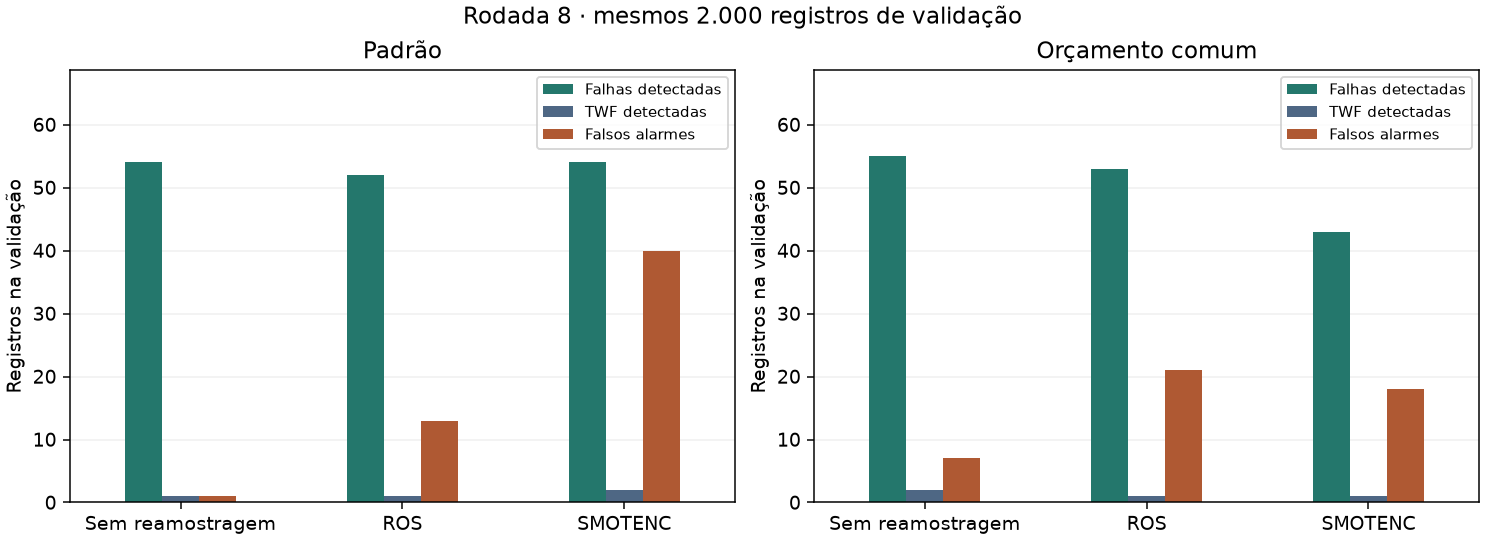

In [68]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
paleta = ["#24776c", "#4e6784", "#af5933"]
for ax, politica in zip(axes, ["Padrão", "Orçamento comum"]):
    dados = resultado8[resultado8["Política"].eq(politica)].set_index("Estratégia")
    dados[["VP", "TWF detectadas", "FP"]].rename(
        columns={"VP": "Falhas detectadas", "FP": "Falsos alarmes"}
    ).plot.bar(ax=ax, rot=0, color=paleta)
    ax.set(title=politica, ylabel="Registros na validação", xlabel="")
    ax.legend(fontsize=8, loc="upper right")
    ax.set_ylim(0, max(resultado8["VP"].max(), resultado8["FP"].max()) * 1.25)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Rodada 8 · mesmos 2.000 registros de validação")
display(fig)
plt.close(fig)


### Leitura dos resultados

No limiar padrão, RF sem reamostragem obteve AP 0,873 e F1 0,878, com 54 falhas detectadas e 1 falsos alarmes. SMOTENC obteve AP 0,781 e F1 0,667, com 54 falhas detectadas e 40 falsos alarmes. Para desgaste, a referência detectou 1/12 e SMOTENC 2/12. As linhas com orçamento comum comparam cortes selecionados no treino. As diferenças de falsos alarmes na validação mostram o custo observado da política.